# Compass EDA: Vehicle and Trajectory Details

Extend `01_traffic_data_eda.ipynb` by examining the same Atlanta extract at the vehicle level. Start with the report structure, identify the observed vehicle population, then measure how often each vehicle appears. This notebook runs independently of the earlier notebooks.

## Contents
1. [Data Structure](#1.-Data-Structure)
2. [Observed Vehicles](#2.-Observed-Vehicles)
3. [Repeated Vehicle Observations](#3.-Repeated-Vehicle-Observations)
4. [Trip Characteristics](#4.-Trip-Characteristics)
5. [Sampling and Continuity](#5.-Sampling-and-Continuity)
6. [Study-Area Exits and Trip Gaps](#6.-Study-Area-Exits-and-Trip-Gaps)
7. [Individual Trajectories](#7.-Individual-Trajectories)

Run the cells in order. Counts describe this Compass extract, not all Atlanta traffic. Tables and figures stay in the notebook. The combined speed–interval figure is also saved under `results/figures/`.



In [1]:
from pathlib import Path
from collections import Counter, defaultdict
from time import perf_counter
import csv, gzip, json, re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'data/raw/Atlanta_compass_aug2026').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Run this notebook from the repository root or notebooks/.')
DATA_DIR = ROOT / 'data/raw/Atlanta_compass_aug2026'
MANIFEST = json.loads((ROOT / 'data/raw/manifest.json').read_text())
TRIP_FILES = sorted(DATA_DIR.glob('trips-*.csv.gz'))
POINT_FILES = sorted(DATA_DIR.glob('points-*.csv.gz'))
MAX_TRIPS = None  # Set a positive integer for a first-row preview, not a representative sample.
assert MAX_TRIPS is None or MAX_TRIPS > 0
for report, files in [('trips', TRIP_FILES), ('points', POINT_FILES)]:
    assert len(files) == next(o['files'] for o in MANIFEST['outputs'] if o['report'] == report)
csv.field_size_limit(sys.maxsize)
pd.set_option('display.max_columns', 10)
SCOPE = 'All trip files' if MAX_TRIPS is None else f'Preview: first {MAX_TRIPS:,} trip rows'
print(f"Period: {MANIFEST['request']['from_date']} to {MANIFEST['request']['to_date']}")
print('Scope:', SCOPE)


def show_compact_figure(figure, width=420, height=360):
    from io import BytesIO
    import base64
    from IPython.display import HTML
    buffer = BytesIO()
    figure.savefig(buffer, format='png', dpi=100)
    encoded = base64.b64encode(buffer.getvalue()).decode('ascii')
    html = (f'<div style="width:{width}px!important;max-width:{width}px!important;'
            f'height:{height}px!important;overflow:hidden;">'
            f'<img src="data:image/png;base64,{encoded}" width="{width}" height="{height}" '
            f'style="display:block;width:{width}px!important;max-width:{width}px!important;'
            f'height:{height}px!important;max-height:{height}px!important;" '
            f'alt="Observation interval analysis" /></div>')
    display(HTML(html))
    plt.close(figure)


Period: 2026-08-01 to 2026-08-31
Scope: All trip files


## 1. Data Structure

Compare the columns, example values, row counts, and units in the Point and Trip reports. Look for shared vehicle/trip identifiers and the available trajectory attributes.

The Point report covers full selected trips, including positions outside the requested area. Trip paths, times, and distances cover the in-area portion. Long example values are shortened for display.


In [2]:
report_examples = {}
for report, files in [('points', POINT_FILES), ('trips', TRIP_FILES)]:
    with gzip.open(files[0], 'rt', newline='') as handle:
        reader = csv.DictReader(handle)
        report_examples[report] = next(reader)
    print(f'{report.title()} report: {len(report_examples[report])} columns')
    display(pd.DataFrame([
        {'Column': key, 'Example value': value if len(value) <= 100 else value[:97] + '...'}
        for key, value in report_examples[report].items()
    ]))

display(pd.DataFrame(MANIFEST['outputs'])[['report', 'rows', 'files']])
display(pd.Series(MANIFEST['units'], name='Unit / convention').to_frame())
for key in ['vehicle_typing', 'id_masking', 'trip_dedup', 'sparse_filter',
            'stationary_filter', 'temporal_filter_basis', 'spatial_extent',
            'trip_geometry_basis', 'acceleration_filter']:
    print(f"{key}: {MANIFEST['methodology'][key]}\n")


Points report: 18 columns
Trips report: 39 columns
vehicle_typing: vehicles are classified under the Austroads vehicle classification scheme, from the reported make and model, falling back to the provider-reported type where the pair is not yet classified

id_masking: VehicleID and TripID are hashed with TO_HEX(MD5(value)) over the complete identifier. No prefix or substring is removed before hashing, so the same vehicle produces the same hash in every extract and IDs are comparable across deliveries. Always applied; not a user option.

trip_dedup: trips are deduplicated before extraction: within each group of overlapping trips for a vehicle, the longest is kept. This removes the same journey reported more than once, and journeys reported as several overlapping records. The Compass platform does not deduplicate, so a trip count here is expected to be slightly lower than the equivalent platform view of the same area and dates

sparse_filter: vehicles with <= 6 points excluded

stationar

,Column,Example value
0,VehicleID,0bf123a1c0a782b300b85b6f04707cd5
1,TripID,6c9848d5ee22cea0ae9d65508b117767
2,Timestamp_Local,2026-08-27 14:31:34
3,Timestamp_UTC,2026-08-27 18:31:34 UTC
4,VehicleType,CAR
5,Make,
6,Model,
7,InArea,true
8,AreaId,1
9,AreaName,Area 1


,Column,Example value
0,VehicleID,59a4320d296163799a49ae217aff8f26
1,TripID,4523a2655a6955fc043c0487ae0ab516
2,VehicleType,CAR
3,Make,
4,Model,
5,origin_in_area,false
6,destination_in_area,true
7,TripRelationship,destination_only
8,StartTimestamp_Local,2026-08-01 00:36:20.246
9,StartTimestamp_UTC,2026-08-01 04:36:20.246 UTC


,report,rows,files
0,points,217201291,149
1,trips,259341,14


,Unit / convention
speed,mph
distance,miles
acceleration,g
timestamps_in,America/New_York
coordinates,WGS 84 (EPSG:4326)
file_format,CSV


## 2. Observed Vehicles

### Load Trip Metadata

Check the number of trip records and distinct vehicles. Review missing identifiers, duplicate keys, and invalid timestamps in the summary table.

Trip records are deduplicated by `VehicleID + TripID + StartTimestamp_UTC`. Observation dates come from the in-area `TimestampPath` values.


In [3]:
metadata_columns = ['VehicleID', 'TripID', 'StartTimestamp_UTC', 'VehicleType', 'Make', 'Model',
                    'StartTimestamp_Local', 'EndTimestamp_Local']
required = set(metadata_columns + ['TimestampPath'])
records, seen = [], {}
vehicle_dates = defaultdict(set)
load_stats = Counter()
date_pattern = re.compile(r'\d{4}-\d{2}-\d{2}')
started = perf_counter()
for file in TRIP_FILES:
    with gzip.open(file, 'rt', newline='') as handle:
        reader = csv.DictReader(handle)
        if not required.issubset(reader.fieldnames):
            raise ValueError(f'Missing required columns in {file.name}')
        for row in reader:
            if MAX_TRIPS is not None and load_stats['rows_read'] >= MAX_TRIPS:
                break
            load_stats['rows_read'] += 1
            key = tuple(row[k].strip() for k in ['VehicleID', 'TripID', 'StartTimestamp_UTC'])
            if not all(key):
                load_stats['missing_key_rows'] += 1
                continue
            dates = tuple(sorted(set(date_pattern.findall(row['TimestampPath']))))
            values = tuple(row[k].strip() for k in metadata_columns)
            signature = (values, dates)
            if key in seen:
                load_stats['duplicate_key_rows'] += 1
                load_stats['conflicting_metadata_or_dates'] += int(seen[key] != signature)
                continue
            seen[key] = signature
            records.append(values)
            vehicle_dates[key[0]].update(dates)
    print(f"{file.name}: {load_stats['rows_read']:,} rows read", flush=True)
    if MAX_TRIPS is not None and load_stats['rows_read'] >= MAX_TRIPS:
        break
trips = pd.DataFrame.from_records(records, columns=metadata_columns)
if trips.empty:
    raise ValueError('No trip records with complete keys.')
for column in ['VehicleType', 'Make', 'Model']:
    trips[column] = trips[column].replace({'': pd.NA, 'null': pd.NA, 'NULL': pd.NA})
for column in ['StartTimestamp_Local', 'EndTimestamp_Local']:
    trips[column] = pd.to_datetime(trips[column], format='mixed', errors='coerce')
load_stats['retained_trip_records'] = len(trips)
load_stats['unique_vehicles'] = trips['VehicleID'].nunique()
load_stats['invalid_start_times'] = int(trips['StartTimestamp_Local'].isna().sum())
load_stats['invalid_end_times'] = int(trips['EndTimestamp_Local'].isna().sum())
load_stats['elapsed_seconds'] = round(perf_counter() - started, 1)
if MAX_TRIPS is None:
    assert load_stats['rows_read'] == next(o['rows'] for o in MANIFEST['outputs'] if o['report'] == 'trips')
display(pd.Series(load_stats, name='Value').to_frame())
print('Scope:', SCOPE)
del records, seen


trips-d3e2550d3e6b-000000000000.csv.gz: 18,732 rows read
trips-d3e2550d3e6b-000000000001.csv.gz: 37,077 rows read
trips-d3e2550d3e6b-000000000002.csv.gz: 55,577 rows read
trips-d3e2550d3e6b-000000000003.csv.gz: 74,140 rows read
trips-d3e2550d3e6b-000000000004.csv.gz: 92,534 rows read
trips-d3e2550d3e6b-000000000005.csv.gz: 111,224 rows read
trips-d3e2550d3e6b-000000000006.csv.gz: 129,994 rows read
trips-d3e2550d3e6b-000000000007.csv.gz: 148,318 rows read
trips-d3e2550d3e6b-000000000008.csv.gz: 166,865 rows read
trips-d3e2550d3e6b-000000000009.csv.gz: 185,254 rows read
trips-d3e2550d3e6b-000000000010.csv.gz: 203,740 rows read
trips-d3e2550d3e6b-000000000011.csv.gz: 222,228 rows read
trips-d3e2550d3e6b-000000000012.csv.gz: 240,704 rows read
trips-d3e2550d3e6b-000000000013.csv.gz: 259,341 rows read
Scope: All trip files


,Value
rows_read,259341.0
retained_trip_records,259341.0
unique_vehicles,237189.0
invalid_start_times,0.0
invalid_end_times,0.0
elapsed_seconds,90.4


### Vehicle Attributes

Check which vehicle types are represented and how much make/model information is missing. Compare vehicle shares with trip shares to see which types contribute disproportionately many trip records.

Each vehicle is counted once. `Not reported` marks a missing attribute; `Multiple reported values` marks conflicting values for the same vehicle.


,Attribute,Vehicles with any value,Vehicles without a value (%),Vehicles with multiple values,Trip records without a value (%)
0,VehicleType,237189,0.0,0,0.0
1,Make,1,100.0,0,100.0
2,Model,0,100.0,0,100.0


,vehicles,trip_records,vehicle_share_pct,trip_share_pct
vehicle_type,,,,
CAR,227523,230273,95.9,88.8
HCV,9666,29068,4.1,11.2


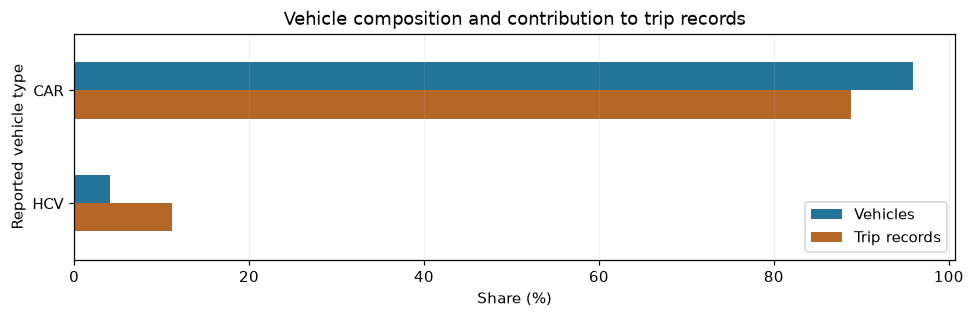

In [4]:
grouped = trips.groupby('VehicleID', sort=True)
vehicles = grouped.size().to_frame('trip_count')
for source, target in [('VehicleType', 'vehicle_type'), ('Make', 'make'), ('Model', 'model')]:
    distinct = grouped[source].nunique()
    vehicles[target] = grouped[source].first().fillna('Not reported')
    vehicles.loc[distinct.gt(1), target] = 'Multiple reported values'

attribute_coverage = []
for source, target in [('VehicleType', 'vehicle_type'), ('Make', 'make'), ('Model', 'model')]:
    attribute_coverage.append({
        'Attribute': source,
        'Vehicles with any value': int(vehicles[target].ne('Not reported').sum()),
        'Vehicles without a value (%)': 100 * vehicles[target].eq('Not reported').mean(),
        'Vehicles with multiple values': int(vehicles[target].eq('Multiple reported values').sum()),
        'Trip records without a value (%)': 100 * trips[source].isna().mean()})
display(pd.DataFrame(attribute_coverage).round(1))

type_summary = vehicles.groupby('vehicle_type').agg(
    vehicles=('trip_count', 'size'), trip_records=('trip_count', 'sum')).sort_values('vehicles', ascending=False)
type_summary['vehicle_share_pct'] = 100 * type_summary['vehicles'] / len(vehicles)
type_summary['trip_share_pct'] = 100 * type_summary['trip_records'] / len(trips)
display(type_summary.round(1))
ax = type_summary[['vehicle_share_pct', 'trip_share_pct']].rename(
    columns={'vehicle_share_pct': 'Vehicles', 'trip_share_pct': 'Trip records'}).plot.barh(
        figsize=(9, max(3, len(type_summary) * .45)), color=['#24749a', '#b56728'])
ax.invert_yaxis()
ax.set(xlabel='Share (%)', ylabel='Reported vehicle type', title='Vehicle composition and contribution to trip records')
ax.grid(axis='x', alpha=.2)
plt.tight_layout()
plt.show()


### Reported Makes and Models

Check the most common reported makes and make/model pairs, counted by distinct vehicles. Compare the number of vehicles with usable information against the total before interpreting the top-ten tables.


In [5]:
for label, columns in [('Make', ['make']), ('Make and model', ['make', 'model'])]:
    valid = vehicles[columns].apply(
        lambda s: ~s.isin(['Not reported', 'Multiple reported values'])).all(axis=1)
    print(f'{label}: {valid.sum():,} of {len(vehicles):,} vehicles with unambiguous values')
    if valid.any():
        display(vehicles.loc[valid].groupby(columns).size().rename('Vehicles')
                .sort_values(ascending=False).head(10).to_frame())
    else:
        print('No unambiguous reported values.')


Make: 1 of 237,189 vehicles with unambiguous values
Make and model: 0 of 237,189 vehicles with unambiguous values
No unambiguous reported values.


,Vehicles
make,
subaru,1


## 3. Repeated Vehicle Observations

### Trip Counts per Vehicle

Check whether vehicles mostly appear once or contribute repeated trips. Focus on the single-trip percentage, upper quantiles, and trip share from the most frequently observed 10% of vehicles.

The plot shows the number of vehicles at each trip count; both axes use logarithmic scales.


Single-trip vehicles: 229,021 (96.6%)
Top 23,719 vehicles (10.0%): 17.7% of trip records


,Trip records per vehicle
count,237189.000000
mean,1.093394
std,1.212493
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
90%,1.000000
95%,1.000000
99%,3.000000


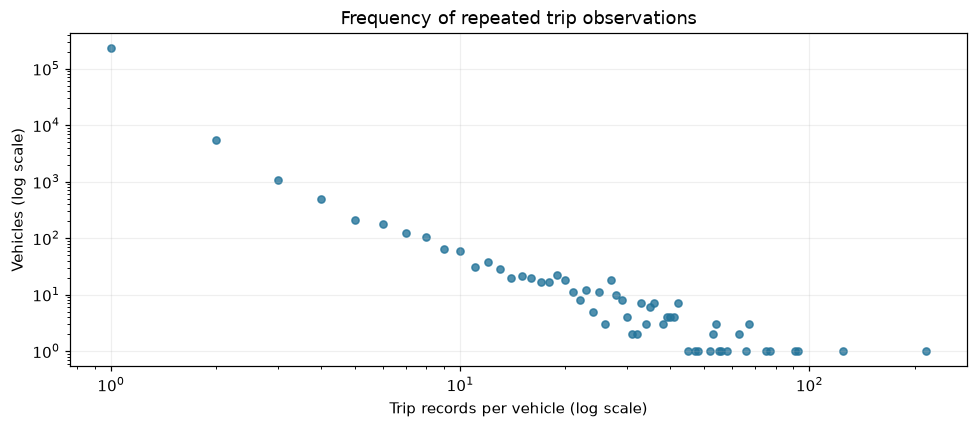

In [6]:
display(vehicles['trip_count'].describe(percentiles=[.25, .5, .75, .9, .95, .99]).to_frame('Trip records per vehicle'))
top_n = max(1, int(np.ceil(.1 * len(vehicles))))
print(f"Single-trip vehicles: {vehicles['trip_count'].eq(1).sum():,} "
      f"({100 * vehicles['trip_count'].eq(1).mean():.1f}%)")
print(f"Top {top_n:,} vehicles ({100 * top_n / len(vehicles):.1f}%): "
      f"{100 * vehicles['trip_count'].nlargest(top_n).sum() / len(trips):.1f}% of trip records")
frequency = vehicles['trip_count'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(frequency.index, frequency.values, s=22, color='#24749a', alpha=.8)
ax.set(xscale='log', yscale='log', xlabel='Trip records per vehicle (log scale)',
       ylabel='Vehicles (log scale)', title='Frequency of repeated trip observations')
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()


### Observed Days and Observation Span

Check whether repeated trips occur on one date or across multiple dates. Compare observed days with the inclusive calendar span between each vehicle's first and last observation.

The right-hand plot's dashed line marks observation on every date within the span. Points below it indicate dates without observations; color shows vehicle counts. The final table lists the ten vehicles with the most trip records.


Vehicles without path dates: 0


,trip_count,observed_days,span_days
count,237189.0,237189.0,237189.0
mean,1.1,1.0,1.1
std,1.2,0.6,1.5
min,1.0,1.0,1.0
25%,1.0,1.0,1.0
50%,1.0,1.0,1.0
75%,1.0,1.0,1.0
90%,1.0,1.0,1.0
95%,1.0,1.0,1.0
99%,3.0,2.0,2.0


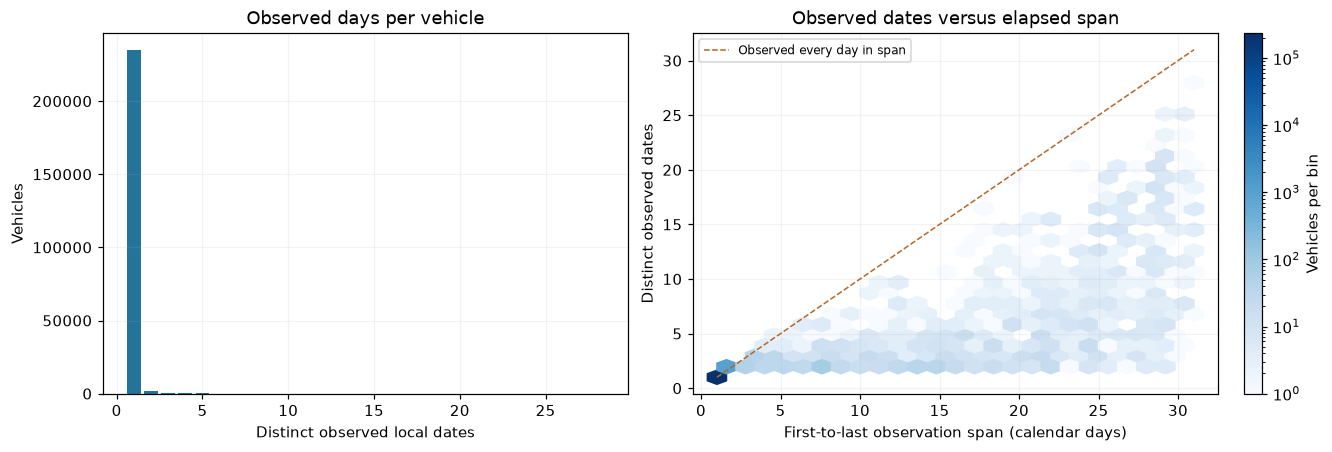

,vehicle_type,trip_count,observed_days,first_observed_date,last_observed_date,span_days
VehicleID,,,,,,
34e5b12b0ff1797632509f4f65b7bebd,HCV,216,19,2026-08-03,2026-08-31,29
9e011fa9f773956b98f13c3f3808e49f,HCV,125,28,2026-08-01,2026-08-31,31
e6484c65b8f2670cd8990b9946b52339,HCV,93,23,2026-08-01,2026-08-23,23
5dd81d5df4d160b31cee89406041b59f,HCV,91,23,2026-08-01,2026-08-31,31
911f7c122a504c955a12ada907d45a1a,HCV,77,17,2026-08-01,2026-08-31,31
38b79d616b8eb41a844755af69b32bc4,HCV,75,25,2026-08-01,2026-08-29,29
ede26f06d04c6b6256eae9a8afa770c4,HCV,67,25,2026-08-01,2026-08-29,29
47c4cdd63bb657a5330a4e3d88aaaa01,HCV,67,21,2026-08-01,2026-08-29,29
b37bfdfb7a1b0d6e732b92c37cc9ec79,HCV,67,20,2026-08-01,2026-08-29,29


In [7]:
def date_summary(vehicle_id):
    dates = sorted(vehicle_dates[vehicle_id])
    return (len(dates), dates[0], dates[-1]) if dates else (np.nan, None, None)

date_rows = [date_summary(v) for v in vehicles.index]
vehicles[['observed_days', 'first_observed_date', 'last_observed_date']] = pd.DataFrame(
    date_rows, index=vehicles.index)
for column in ['first_observed_date', 'last_observed_date']:
    vehicles[column] = pd.to_datetime(vehicles[column])
vehicles['observed_days'] = pd.to_numeric(vehicles['observed_days'])
vehicles['span_days'] = (vehicles['last_observed_date'] - vehicles['first_observed_date']).dt.days + 1
print('Vehicles without path dates:', int(vehicles['observed_days'].isna().sum()))
display(vehicles[['trip_count', 'observed_days', 'span_days']].describe(
    percentiles=[.25, .5, .75, .9, .95, .99]).round(1))

day_frequency = vehicles['observed_days'].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].bar(day_frequency.index, day_frequency.values, color='#24749a')
axes[0].set(xlabel='Distinct observed local dates', ylabel='Vehicles', title='Observed days per vehicle')
valid_dates = vehicles.dropna(subset=['observed_days', 'span_days'])
density = axes[1].hexbin(valid_dates['span_days'], valid_dates['observed_days'],
               gridsize=25, mincnt=1, bins='log', cmap='Blues')
fig.colorbar(density, ax=axes[1], label='Vehicles per bin')
limit = max(1, valid_dates['span_days'].max()) if not valid_dates.empty else 1
axes[1].plot([1, limit], [1, limit], '--', color='#b56728', lw=1, label='Observed every day in span')
axes[1].set(xlabel='First-to-last observation span (calendar days)', ylabel='Distinct observed dates',
            title='Observed dates versus elapsed span')
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=.15)
plt.show()

display(vehicles[['vehicle_type', 'trip_count', 'observed_days',
                  'first_observed_date', 'last_observed_date', 'span_days']]
        .sort_values('trip_count', ascending=False).head(10))


## 4. Trip Characteristics

### Prepare Trip and Sampling Measures

Read the retained trip records to collect duration, distance, point counts, and adjacent-observation measures. Check the processing summary for missing paths, mismatched array lengths, and invalid coordinates or times before interpreting the following plots.

This pass uses in-area Trip report paths. Gaps over 10 seconds and steps over 100 meters are screening thresholds from notebook 01, not confirmed errors. A small seeded sample is retained for individual trajectory plots.


In [8]:
KEY_COLUMNS = ['VehicleID', 'TripID', 'StartTimestamp_UTC']
GAP_THRESHOLD_S = 10.0
STEP_THRESHOLD_M = 100.0
SAMPLE_SEED = 42
MAX_SAMPLE_POINTS = 10000
PAIR_GAP_EDGES = np.array([0, .5, 1, 2, 3, 5, 10, 30, 60, 300, np.inf])
positive_gap_counts = np.zeros(len(PAIR_GAP_EDGES) - 1, dtype=np.int64)
scan_stats = Counter()
SPEED_PAIR_EDGES = np.r_[0, 1, np.arange(2, 102, 2), 120, 150, np.inf]
INTERVAL_PAIR_EDGES = np.array([.001, .01, .1, .5, 1, 2, 3, 5, 10, 15, 30,
                                60, 120, 300, 600, 1800, 3600, 10800, 43200, 86400, np.inf])
speed_interval_counts = np.zeros((len(SPEED_PAIR_EDGES) - 1, len(INTERVAL_PAIR_EDGES) - 1), dtype=np.int64)
speed_interval_groups = [Counter() for _ in range(4)]
pair_speed_stats = Counter()
metric_rows = []
retained_keys = set(trips[KEY_COLUMNS].itertuples(index=False, name=None))
processed_keys = set()
sample_candidates = defaultdict(list)
sample_seen = Counter()
sample_rng = np.random.default_rng(SAMPLE_SEED)


def numeric_path(value, coordinates=False):
    text = value.strip()
    if not text:
        return np.array([], dtype=float)
    if coordinates:
        # One comma-delimited item is one position, including null placeholders.
        positions = text.split(',')
        expanded = ['nan nan' if item.strip().lower() in ('', 'null', 'nan') else item
                    for item in positions]
        values = np.fromstring(' '.join(expanded), sep=' ')
        if len(values) == 2 * len(positions):
            return values
        pairs = np.full((len(positions), 2), np.nan)
        for i, item in enumerate(positions):
            parts = item.split()
            if len(parts) == 2:
                pairs[i] = pd.to_numeric(pd.Series(parts), errors='coerce')
        return pairs.ravel()
    text = re.sub(r'(?i)\bnull\b', 'nan', text)
    tokens = text.split(',')
    try:
        return np.asarray(tokens, dtype=float)
    except ValueError:
        return pd.to_numeric(pd.Series(tokens), errors='coerce').to_numpy(dtype=float)


def timestamp_path(value):
    if not value.strip():
        return np.array([], dtype='datetime64[ms]')
    tokens = [t.strip() if t.strip().lower() not in ('', 'null', 'nat') else 'NaT'
              for t in value.split(',')]
    try:
        return np.asarray(tokens, dtype='datetime64[ms]')
    except ValueError:
        return pd.to_datetime(tokens, format='mixed', errors='coerce').to_numpy(dtype='datetime64[ms]')


def scalar_number(value):
    try:
        return float(value)
    except (ValueError, TypeError):
        return np.nan


def great_circle_steps(coords):
    lon, lat = np.radians(coords[:, 0]), np.radians(coords[:, 1])
    a = np.sin(np.diff(lat) / 2)**2 + np.cos(lat[:-1]) * np.cos(lat[1:]) * np.sin(np.diff(lon) / 2)**2
    return 2 * 6371008.8 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


scan_started = perf_counter()
for file in TRIP_FILES:
    with gzip.open(file, 'rt', newline='') as handle:
        for row in csv.DictReader(handle):
            key = tuple(row[k].strip() for k in KEY_COLUMNS)
            if key not in retained_keys or key in processed_keys:
                continue
            processed_keys.add(key)
            times = timestamp_path(row['TimestampPath'])
            flat_coords = numeric_path(row['SnappedPath'], coordinates=True)
            malformed_coords = len(flat_coords) % 2 != 0
            coords = flat_coords.reshape(-1, 2) if not malformed_coords else np.empty((0, 2))
            time_valid = ~np.isnat(times)
            coord_valid = (np.isfinite(coords).all(axis=1)
                           & (np.abs(coords[:, 0]) <= 180) & (np.abs(coords[:, 1]) <= 90))
            aligned = not malformed_coords and len(coords) == len(times)
            dt = np.diff(times).astype('timedelta64[ms]').astype(float) / 1000
            valid_time_pair = time_valid[:-1] & time_valid[1:]
            positive = valid_time_pair & (dt > 0)
            positive_gap_counts += np.histogram(dt[positive], bins=PAIR_GAP_EDGES)[0]
            scan_stats['timestamp_pairs'] += len(dt)
            scan_stats['pairs_with_missing_time'] += int((~valid_time_pair).sum())
            scan_stats['nonincreasing_time_pairs'] += int((valid_time_pair & (dt <= 0)).sum())
            scan_stats['positive_time_pairs'] += int(positive.sum())
            scan_stats['gaps_over_10_seconds'] += int((positive & (dt > GAP_THRESHOLD_S)).sum())
            scan_stats['invalid_time_points'] += int((~time_valid).sum())
            scan_stats['invalid_coordinate_points'] += int((~coord_valid).sum())
            scan_stats['trips_with_empty_time_path'] += int(len(times) == 0)
            scan_stats['trips_with_malformed_coordinate_pairs'] += int(malformed_coords)
            scan_stats['trips_with_unaligned_time_coordinates'] += int(not aligned)
            step_count = np.nan
            max_step = np.nan
            if aligned:
                steps = great_circle_steps(coords)
                spatial_pairs = coord_valid[:-1] & coord_valid[1:]
                usable = spatial_pairs & positive
                step_count = int((usable & (steps > STEP_THRESHOLD_M)).sum())
                max_step = float(steps[usable].max()) if usable.any() else np.nan
                scan_stats['usable_time_coordinate_pairs'] += int(usable.sum())
                scan_stats['steps_over_100_meters'] += step_count
            positive_dt = dt[positive]
            gap_quantiles = np.quantile(positive_dt, [.1, .5, .9]) if len(positive_dt) else [np.nan] * 3
            speed_values = numeric_path(row['SpeedPath_mph'])
            speed_aligned = len(speed_values) == len(times)
            scan_stats['trips_with_unaligned_speed_times'] += int(not speed_aligned)
            if speed_aligned:
                preceding_speed = speed_values[:-1]
                valid_speed = np.isfinite(preceding_speed) & (preceding_speed >= 0)
                valid_pair = positive & valid_speed
                pair_speed_stats['positive_pairs_with_invalid_speed'] += int((positive & ~valid_speed).sum())
                pair_speed_stats['included_pairs'] += int(valid_pair.sum())
                speed_interval_counts += np.histogram2d(
                    preceding_speed[valid_pair], dt[valid_pair],
                    bins=[SPEED_PAIR_EDGES, INTERVAL_PAIR_EDGES])[0].astype(np.int64)
                interval_ms = np.diff(times).astype('timedelta64[ms]').astype(np.int64)
                for group, (lower, upper) in enumerate([(0, 1), (1, 15), (15, 35), (35, np.inf)]):
                    selected = valid_pair & (preceding_speed >= lower) & (preceding_speed < upper)
                    values, counts = np.unique(interval_ms[selected], return_counts=True)
                    speed_interval_groups[group].update(dict(zip(values.tolist(), counts.tolist())))
            else:
                pair_speed_stats['positive_pairs_in_unaligned_paths'] += int(positive.sum())
            duration = scalar_number(row['TravelTimeSeconds'])
            max_gap = float(dt[positive].max()) if positive.any() else np.nan
            metric_rows.append(dict(zip(KEY_COLUMNS, key), duration_s=duration,
                distance_mi=scalar_number(row['TravelDistance_mi']), path_points=len(times),
                reported_points=scalar_number(row['total_points']),
                full_trip_points=scalar_number(row['points_total']),
                positive_pairs=int(positive.sum()), max_gap_s=max_gap,
                gap_over_10_count=int((positive & (dt > GAP_THRESHOLD_S)).sum()),
                nonincreasing_pairs=int((valid_time_pair & (dt <= 0)).sum()),
                steps_over_100_count=step_count, max_step_m=max_step,
                aligned_time_coordinates=aligned,
                gap_p10_s=gap_quantiles[0], median_gap_s=gap_quantiles[1], gap_p90_s=gap_quantiles[2]))
            eligible = (aligned and 10 <= len(times) <= MAX_SAMPLE_POINTS
                        and time_valid.all() and coord_valid.all()
                        and positive.all() and np.isfinite(duration) and duration >= 30)
            if eligible:
                groups = ['Short (up to 2 min)' if duration <= 120 else
                          'Medium (2–15 min)' if duration <= 900 else 'Long (over 15 min)']
                if row['VehicleType'].strip() == 'HCV':
                    groups.append('HCV example')
                if max_gap > GAP_THRESHOLD_S:
                    groups.append('Gap over 10 s')
                for group in groups:
                    sample_seen[group] += 1
                    pool = sample_candidates[group]
                    slot = len(pool) if len(pool) < 6 else int(sample_rng.integers(sample_seen[group]))
                    if slot < 6:
                        sample = {'key': key, 'vehicle_type': row['VehicleType'].strip(),
                                  'times': times, 'coords': coords,
                                  'speed': numeric_path(row['SpeedPath_mph']),
                                  'xacc': numeric_path(row['XAccPath']),
                                  'yacc': numeric_path(row['YAccPath'])}
                        if slot == len(pool):
                            pool.append(sample)
                        else:
                            pool[slot] = sample
    print(f'{file.name}: {len(processed_keys):,} retained records processed', flush=True)
    if len(processed_keys) == len(retained_keys):
        break
assert processed_keys == retained_keys, 'Some retained trips were not found.'
assert int(speed_interval_counts.sum()) == pair_speed_stats['included_pairs']
assert sum(sum(group.values()) for group in speed_interval_groups) == pair_speed_stats['included_pairs']
assert (pair_speed_stats['included_pairs'] + pair_speed_stats['positive_pairs_with_invalid_speed']
        + pair_speed_stats['positive_pairs_in_unaligned_paths']) == scan_stats['positive_time_pairs']
trip_metrics = trips.merge(pd.DataFrame(metric_rows), on=KEY_COLUMNS, validate='one_to_one')
scan_stats['processed_trip_records'] = len(trip_metrics)
scan_stats['elapsed_seconds'] = round(perf_counter() - scan_started, 1)
display(pd.Series(scan_stats, name='Count / seconds').to_frame())
print('Scope:', SCOPE)
del metric_rows, retained_keys, processed_keys


trips-d3e2550d3e6b-000000000000.csv.gz: 18,732 retained records processed
trips-d3e2550d3e6b-000000000001.csv.gz: 37,077 retained records processed
trips-d3e2550d3e6b-000000000002.csv.gz: 55,577 retained records processed
trips-d3e2550d3e6b-000000000003.csv.gz: 74,140 retained records processed
trips-d3e2550d3e6b-000000000004.csv.gz: 92,534 retained records processed
trips-d3e2550d3e6b-000000000005.csv.gz: 111,224 retained records processed
trips-d3e2550d3e6b-000000000006.csv.gz: 129,994 retained records processed
trips-d3e2550d3e6b-000000000007.csv.gz: 148,318 retained records processed
trips-d3e2550d3e6b-000000000008.csv.gz: 166,865 retained records processed
trips-d3e2550d3e6b-000000000009.csv.gz: 185,254 retained records processed
trips-d3e2550d3e6b-000000000010.csv.gz: 203,740 retained records processed
trips-d3e2550d3e6b-000000000011.csv.gz: 222,228 retained records processed
trips-d3e2550d3e6b-000000000012.csv.gz: 240,704 retained records processed
trips-d3e2550d3e6b-00000000001

,Count / seconds
timestamp_pairs,53690398.0
pairs_with_missing_time,0.0
nonincreasing_time_pairs,7.0
positive_time_pairs,53690391.0
gaps_over_10_seconds,1528180.0
invalid_time_points,0.0
invalid_coordinate_points,611174.0
trips_with_empty_time_path,0.0
trips_with_malformed_coordinate_pairs,0.0
trips_with_unaligned_time_coordinates,0.0


### Duration, Distance, and Point Count

Check the typical trip size and the upper tail in duration, in-area distance, and timestamp count. Compare `path_points` with the supplied `total_points`; `points_total` refers to the full trip and can be larger.

Tables use all retained records. Histograms show nonnegative values up to each measure's 99th percentile; the excluded upper tail is counted in each title.


Timestamp count differs from total_points: 17693


,duration_s,distance_mi,path_points,reported_points,full_trip_points
count,259341.00,133967.00,259341.00,259341.00,259341.00
mean,655.98,4.33,208.03,207.73,782.73
std,718.67,3.06,249.80,249.13,1060.72
min,1.00,0.00,2.00,2.00,8.00
25%,297.00,1.37,52.00,52.00,143.00
50%,489.00,4.36,138.00,138.00,458.00
75%,824.00,7.15,263.00,263.00,1007.00
90%,1275.00,7.64,463.00,463.00,1638.00
95%,1679.00,8.06,669.00,668.00,2949.00
99%,3128.00,10.28,1227.00,1222.60,5543.60


,Measure,Missing,Negative,Zero
0,In-area duration (seconds),0,0,0
1,In-area distance (miles),125374,0,75
2,Timestamp count,0,0,0


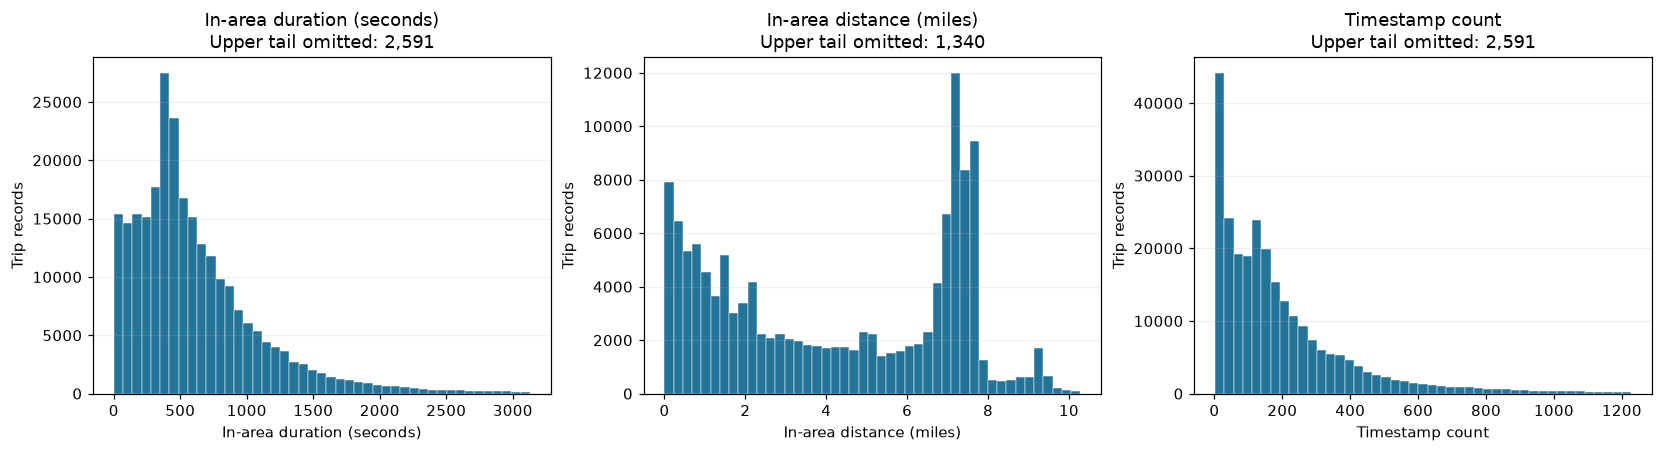

In [9]:
measures = [('duration_s', 'In-area duration (seconds)'),
            ('distance_mi', 'In-area distance (miles)'), ('path_points', 'Timestamp count')]
display(trip_metrics[[m[0] for m in measures] + ['reported_points', 'full_trip_points']]
        .describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(2))
checks = []
for key, label in measures:
    values = trip_metrics[key]
    checks.append({'Measure': label, 'Missing': int(values.isna().sum()),
                   'Negative': int(values.lt(0).sum()), 'Zero': int(values.eq(0).sum())})
display(pd.DataFrame(checks))
print('Timestamp count differs from total_points:',
      int(trip_metrics['path_points'].ne(trip_metrics['reported_points']).sum()))
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, (key, label) in zip(axes, measures):
    values = trip_metrics.loc[trip_metrics[key].ge(0), key].dropna()
    cutoff = values.quantile(.99)
    shown = values[values <= cutoff]
    ax.hist(shown, bins=45, color='#24749a', edgecolor='white', linewidth=.3)
    ax.set(xlabel=label, ylabel='Trip records',
           title=f'{label}\nUpper tail omitted: {(values > cutoff).sum():,}')
    ax.grid(axis='y', alpha=.2)
plt.show()


## 5. Sampling and Continuity

### Time between Observations

Check the distribution of positive adjacent timestamp differences across all trip paths. Missing-time and nonincreasing pairs are excluded and counted separately. Long intervals remain in the distribution.

This plot weights each observation pair equally; the following analyses compare intervals within each trip.


Pairs with missing times: 0
Duplicate or reverse-time pairs: 7
Positive pairs over 10 s: 1,528,180 (2.85%)
Trips with a gap over 10 s: 221,705 (85.49%)


,Interval (s),Pairs,Share of positive pairs (%)
0,"(0, 0.5)",24599,0.05
1,"[0.5, 1)",164004,0.31
2,"[1, 2)",33117126,61.68
3,"[2, 3)",6690080,12.46
4,"[3, 5)",6847161,12.75
5,"[5, 10)",4741692,8.83
6,"[10, 30)",1464141,2.73
7,"[30, 60)",358164,0.67
8,"[60, 300)",266853,0.50
9,300+,16571,0.03



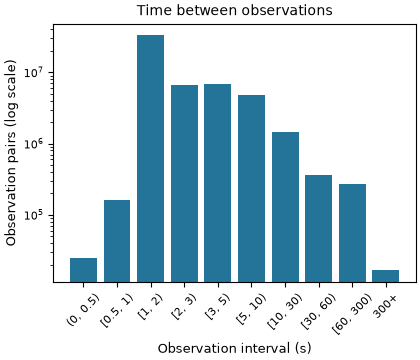

In [18]:
gap_labels = ['(0, 0.5)', '[0.5, 1)', '[1, 2)', '[2, 3)', '[3, 5)',
              '[5, 10)', '[10, 30)', '[30, 60)', '[60, 300)', '300+']
gap_table = pd.DataFrame({'Interval (s)': gap_labels, 'Pairs': positive_gap_counts})
gap_table['Share of positive pairs (%)'] = 100 * gap_table['Pairs'] / max(1, scan_stats['positive_time_pairs'])
display(gap_table.round(2))
print('Pairs with missing times:', scan_stats['pairs_with_missing_time'])
print('Duplicate or reverse-time pairs:', scan_stats['nonincreasing_time_pairs'])
print(f"Positive pairs over 10 s: {scan_stats['gaps_over_10_seconds']:,} "
      f"({100 * scan_stats['gaps_over_10_seconds'] / max(1, scan_stats['positive_time_pairs']):.2f}%)")
has_gaps = trip_metrics['gap_over_10_count'].gt(0)
print(f'Trips with a gap over 10 s: {has_gaps.sum():,} ({100 * has_gaps.mean():.2f}%)')
with plt.rc_context({'font.size': 9, 'axes.titlesize': 10, 'axes.labelsize': 9,
                     'xtick.labelsize': 8, 'ytick.labelsize': 8}):
    fig, ax = plt.subplots(figsize=(4.2, 3.6), constrained_layout=True)
    ax.bar(np.arange(len(gap_labels)), positive_gap_counts, color='#24749a')
    ax.set(xticks=np.arange(len(gap_labels)), xticklabels=gap_labels,
           xlabel='Observation interval (s)', ylabel='Observation pairs (log scale)',
           yscale='log', title='Time between observations')
    ax.tick_params(axis='x', labelrotation=45)
    show_compact_figure(fig)


### Interval Variation within Trips

Check whether a trip's usual interval also describes its slower sampling periods. Each trip contributes one point: its median interval and its 90th-to-10th percentile interval ratio. A ratio near one indicates similar central intervals; larger ratios indicate variation within that trip.

Use trips with at least ten positive intervals. The percentile ratio summarizes the central 80% and can miss a single rare long gap. No upper-tail trimming is applied.


Trips with at least 10 positive intervals: 242,081 / 259,341


,median_gap_s,gap_p10_s,gap_p90_s,p90_p10_ratio
count,242081.00,242081.00,242081.00,242081.00
mean,4.05,2.80,8.76,5.37
std,10.54,9.06,24.40,3.61
min,1.00,0.01,1.00,1.00
25%,2.00,1.00,5.00,3.00
50%,2.00,1.00,6.00,6.00
75%,2.00,1.00,7.00,7.00
90%,3.00,1.00,9.10,8.00
95%,10.00,10.00,30.00,8.90
99%,60.00,60.00,62.20,12.10



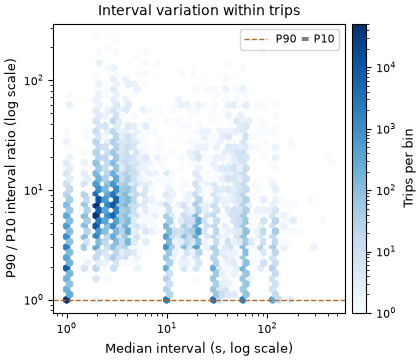

In [19]:
interval_variation = trip_metrics.loc[trip_metrics['positive_pairs'].ge(10)].copy()
interval_variation['p90_p10_ratio'] = interval_variation['gap_p90_s'] / interval_variation['gap_p10_s']
print(f'Trips with at least 10 positive intervals: {len(interval_variation):,} / {len(trip_metrics):,}')
display(interval_variation[['median_gap_s', 'gap_p10_s', 'gap_p90_s', 'p90_p10_ratio']]
        .describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(2))
with plt.rc_context({'font.size': 9, 'axes.titlesize': 10, 'axes.labelsize': 9,
                     'xtick.labelsize': 8, 'ytick.labelsize': 8}):
    fig, ax = plt.subplots(figsize=(4.2, 3.6), constrained_layout=True)
    if not interval_variation.empty:
        density = ax.hexbin(interval_variation['median_gap_s'], interval_variation['p90_p10_ratio'],
                            xscale='log', yscale='log', gridsize=45, mincnt=1, bins='log', cmap='Blues')
        fig.colorbar(density, ax=ax, label='Trips per bin', fraction=.055, pad=.025)
    ax.axhline(1, color='#b56728', ls='--', lw=1, label='P90 = P10')
    ax.set(xlabel='Median interval (s, log scale)',
           ylabel='P90 / P10 interval ratio (log scale)', title='Interval variation within trips')
    ax.legend(fontsize=8, loc='upper right')
    show_compact_figure(fig)


In [ ]:
import traci
import pandas as pd

traci.start(["sumo", "-c", str(CONFIG_FILE)])

records = []

try:
    while traci.simulation.getMinExpectedNumber() > 0:
        traci.simulationStep()

        records.append({
            "time": traci.simulation.getTime(),
            "phase": traci.trafficlight.getPhase("center"),
            "north": traci.edge.getLastStepHaltingNumber("north_in"),
            "south": traci.edge.getLastStepHaltingNumber("south_in"),
            "east": traci.edge.getLastStepHaltingNumber("east_in"),
            "west": traci.edge.getLastStepHaltingNumber("west_in"),
        })

finally:
    traci.close()

df_signal = pd.DataFrame(records)

df_signal["NS_waiting"] = df_signal["north"] + df_signal["south"]
df_signal["EW_waiting"] = df_signal["east"] + df_signal["west"]

display(df_signal.head(20))

 Retrying in 1 seconds
Step #653.00 (0ms ?*RT. ?UPS, TraCI: 0ms, vehicles TOT 200 ACT 0 BUF 0)                   


,time,phase,north,south,east,west,NS_waiting,EW_waiting
0,1.0,0,0,0,0,0,0,0
1,2.0,0,0,0,0,0,0,0
2,3.0,0,0,0,0,0,0,0
3,4.0,0,0,0,0,0,0,0
4,5.0,0,0,0,0,0,0,0
5,6.0,0,0,0,0,0,0,0
6,7.0,0,0,0,0,0,0,0
7,8.0,0,0,0,0,0,0,0
8,9.0,0,0,0,0,0,0,0
9,10.0,0,0,0,0,0,0,0


### Observation Interval and Preceding Speed

Treat each adjacent observation pair as one record: speed at its first timestamp versus time until its next timestamp. The heatmap counts these pairs; the cumulative curves compare all individual intervals within four preceding-speed ranges.

Keep positive intervals with valid timestamps and finite, nonnegative preceding speed. Exclude entire paths from this analysis only when speed and timestamp lengths differ. No minimum count per trip, speed cap, interval trimming, interpolation, or trip-level median aggregation is applied. Speeds of 150+ mph share an overflow bin in the heatmap; all remain in the 35+ mph distribution. Empty outer bins are omitted from the displayed axes.

Each pair has equal weight, so frequently sampled trips contribute more records. These are descriptive relationships: preceding speed does not describe motion throughout an interval, and observations from the same vehicle are related.


Analysis unit: one adjacent observation pair, weighted equally.
Saved combined figure: results/figures/speed_observation_interval.png


,Pairs
positive_pairs_with_invalid_speed,0
included_pairs,53690391


,Preceding speed,Observation pairs,P10 interval (s),Median interval (s),P90 interval (s),Intervals >10 s (%)
0,<1 mph,2971243,1.0,1.0,17.0,13.31
1,1–<15 mph,13737374,1.0,1.0,6.0,3.97
2,15–<35 mph,17654746,1.0,1.0,5.0,1.65
3,35+ mph,19327028,1.0,1.0,5.0,1.53


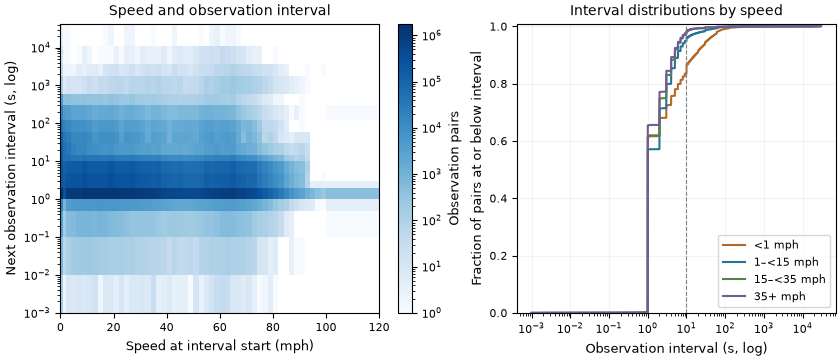

In [24]:
from matplotlib.colors import LogNorm


def weighted_interval_quantiles(values_ms, counts, probabilities):
    # Exact linear-interpolated sample quantiles from unique millisecond values.
    cumulative = np.cumsum(counts)
    ranks = (cumulative[-1] - 1) * np.asarray(probabilities)
    lower = np.floor(ranks).astype(np.int64)
    upper = np.ceil(ranks).astype(np.int64)
    low_values = values_ms[np.searchsorted(cumulative, lower, side='right')]
    high_values = values_ms[np.searchsorted(cumulative, upper, side='right')]
    return (low_values + (high_values - low_values) * (ranks - lower)) / 1000


print('Analysis unit: one adjacent observation pair, weighted equally.')
display(pd.Series(pair_speed_stats, name='Pairs').to_frame())
speed_group_labels = ['<1 mph', '1–<15 mph', '15–<35 mph', '35+ mph']
group_distributions, summary_rows = [], []
for label, counts_by_ms in zip(speed_group_labels, speed_interval_groups):
    if not counts_by_ms:
        continue
    values_ms = np.array(sorted(counts_by_ms), dtype=np.int64)
    counts = np.array([counts_by_ms[value] for value in values_ms], dtype=np.int64)
    quantiles = weighted_interval_quantiles(values_ms, counts, [.1, .5, .9])
    group_distributions.append((label, values_ms / 1000, counts))
    summary_rows.append({'Preceding speed': label, 'Observation pairs': int(counts.sum()),
                         'P10 interval (s)': quantiles[0], 'Median interval (s)': quantiles[1],
                         'P90 interval (s)': quantiles[2],
                         'Intervals >10 s (%)': 100 * counts[values_ms > 10000].sum() / counts.sum()})
display(pd.DataFrame(summary_rows).round(2))

with plt.rc_context({'font.size': 9, 'axes.titlesize': 10, 'axes.labelsize': 9,
                     'xtick.labelsize': 8, 'ytick.labelsize': 8}):
    fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.6), constrained_layout=True)
    ax = axes[0]
    if speed_interval_counts.any():
        occupied_x = np.flatnonzero(speed_interval_counts.sum(axis=1))
        occupied_y = np.flatnonzero(speed_interval_counts.sum(axis=0))
        ix, iy = slice(occupied_x[0], occupied_x[-1] + 1), slice(occupied_y[0], occupied_y[-1] + 1)
        plot_speed_edges = SPEED_PAIR_EDGES.copy()
        plot_speed_edges[-1] = 180  # Display width for the 150+ mph overflow bin.
        plot_interval_edges = INTERVAL_PAIR_EDGES.copy()
        plot_interval_edges[-1] = 172800  # Display width for the 24+ hour overflow bin.
        values = speed_interval_counts[ix, iy].T
        mesh = ax.pcolormesh(plot_speed_edges[ix.start:ix.stop + 1],
                             plot_interval_edges[iy.start:iy.stop + 1],
                             np.ma.masked_equal(values, 0), cmap='Blues',
                             norm=LogNorm(vmin=1, vmax=max(2, int(values.max()))), shading='flat')
        fig.colorbar(mesh, ax=ax, label='Observation pairs', fraction=.055, pad=.025)
        if occupied_x[-1] == len(SPEED_PAIR_EDGES) - 2:
            ax.set_xticks([0, 50, 100, 165], ['0', '50', '100', '150+'])
        if occupied_y[-1] == len(INTERVAL_PAIR_EDGES) - 2:
            ax.set_yticks([.01, 1, 100, 10000, 120000], ['0.01', '1', '100', '10000', '24h+'])
    ax.set(yscale='log', xlabel='Speed at interval start (mph)',
           ylabel='Next observation interval (s, log)', title='Speed and observation interval')
    ax = axes[1]
    for (label, values_s, counts), color in zip(group_distributions, ['#b56728', '#24749a', '#55824b', '#725a95']):
        cumulative_fraction = np.cumsum(counts) / counts.sum()
        ax.step(values_s, cumulative_fraction, where='post', label=label, color=color, lw=1.5)
    ax.axvline(10, color='gray', ls='--', lw=.8)
    ax.set(xscale='log', ylim=(0, 1.01), xlabel='Observation interval (s, log)',
           ylabel='Fraction of pairs at or below interval', title='Interval distributions by speed')
    ax.legend(fontsize=8, loc='lower right')
    ax.grid(alpha=.15)
    figure_path = ROOT / 'results/figures/speed_observation_interval.png'
    figure_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_path, dpi=300, facecolor='white')
    from io import BytesIO
    from IPython.display import Image
    image_buffer = BytesIO()
    fig.savefig(image_buffer, format='png', dpi=100)
    display(Image(data=image_buffer.getvalue(), width=840, height=360))
    plt.close(fig)
print(f'Saved combined figure: {figure_path.relative_to(ROOT)}')


In [ ]:
import traci
import pandas as pd

traci.start(["sumo", "-c", str(CONFIG_FILE)])

records = []

try:
    while traci.simulation.getMinExpectedNumber() > 0:
        traci.simulationStep()

        records.append({
            "time": traci.simulation.getTime(),
            "phase": traci.trafficlight.getPhase("center"),
            "north": traci.edge.getLastStepHaltingNumber("north_in"),
            "south": traci.edge.getLastStepHaltingNumber("south_in"),
            "east": traci.edge.getLastStepHaltingNumber("east_in"),
            "west": traci.edge.getLastStepHaltingNumber("west_in"),
        })

finally:
    traci.close()

df_signal = pd.DataFrame(records)

df_signal["NS_waiting"] = df_signal["north"] + df_signal["south"]
df_signal["EW_waiting"] = df_signal["east"] + df_signal["west"]

display(df_signal.head(20))

 Retrying in 1 seconds
Step #653.00 (0ms ?*RT. ?UPS, TraCI: 0ms, vehicles TOT 200 ACT 0 BUF 0)                   


,time,phase,north,south,east,west,NS_waiting,EW_waiting
0,1.0,0,0,0,0,0,0,0
1,2.0,0,0,0,0,0,0,0
2,3.0,0,0,0,0,0,0,0
3,4.0,0,0,0,0,0,0,0
4,5.0,0,0,0,0,0,0,0
5,6.0,0,0,0,0,0,0,0
6,7.0,0,0,0,0,0,0,0
7,8.0,0,0,0,0,0,0,0
8,9.0,0,0,0,0,0,0,0
9,10.0,0,0,0,0,0,0,0


### Position Steps and Path Alignment

Check whether coordinates and timestamps can be paired and how often consecutive observed positions are more than 100 meters apart. Distances use consecutive snapped coordinates with valid positions and increasing timestamps.

Compare large steps with time gaps: a large distance over a long interval does not establish a GPS error. In-area paths may also contain gaps between separate visits to the requested area. The flags can overlap.


In [13]:
quality_flags = pd.DataFrame({
    'Flag': ['Unaligned time/coordinate arrays', 'Nonincreasing timestamps',
             'Time gap over 10 s', 'Position step over 100 m'],
    'Trip records': [int((~trip_metrics['aligned_time_coordinates']).sum()),
                     int(trip_metrics['nonincreasing_pairs'].gt(0).sum()),
                     int(trip_metrics['gap_over_10_count'].gt(0).sum()),
                     int(trip_metrics['steps_over_100_count'].gt(0).sum())]})
quality_flags['Share of retained trips (%)'] = 100 * quality_flags['Trip records'] / len(trip_metrics)
display(quality_flags.round(2))
spatial_trips = trip_metrics.loc[trip_metrics['aligned_time_coordinates']]
display(pd.crosstab(spatial_trips['gap_over_10_count'].gt(0),
                    spatial_trips['steps_over_100_count'].gt(0),
                    rownames=['Gap over 10 s'], colnames=['Step over 100 m']))
print('Step analysis excludes unaligned paths:', int((~trip_metrics['aligned_time_coordinates']).sum()))
display(trip_metrics[['max_step_m']].describe(percentiles=[.5, .9, .95, .99]).round(1))


Step analysis excludes unaligned paths: 0


,Flag,Trip records,Share of retained trips (%)
0,Unaligned time/coordinate arrays,0,0.00
1,Nonincreasing timestamps,3,0.00
2,Time gap over 10 s,221705,85.49
3,Position step over 100 m,200323,77.24


Step over 100 m,False,True
Gap over 10 s,,
False,24676,12960
True,34342,187363


,max_step_m
count,258976.0
mean,456.0
std,735.1
min,0.0
50%,235.4
90%,1187.8
95%,1736.7
99%,3799.7
max,12672.6


## 6. Study-Area Exits and Trip Gaps

### Compare In-Area Trip Paths with Full Point Records

Check whether long gaps in Trip paths occur because a vehicle leaves the study area and later returns. Select three diagnostic examples and match their full Point records by VehicleID and TripID. Point observations inside each gap are classified with the supplied `InArea` flag.

Trip paths contain only in-area observations; Point records cover the full selected trip. Outside-area points between in-area gap endpoints provide evidence of an exit and re-entry. A gap with no intermediate Point observations remains unexplained by area filtering alone. These examples do not estimate prevalence across all trips.

This section runs before the individual trajectory plots. It scans every compressed Point file and checks the row count against the manifest; the scan can take several minutes. No intermediate result files are exported.


In [16]:
from concurrent.futures import ThreadPoolExecutor, as_completed
import io

def select_diagnostic_samples():
    selected, chosen = [], set()
    for label in ['Short (up to 2 min)', 'Medium (2–15 min)', 'Long (over 15 min)',
                  'HCV example', 'Gap over 10 s']:
        candidates = [sample for sample in sample_candidates[label] if sample['key'] not in chosen]
        if candidates:
            sample = candidates[0].copy()
            sample['label'] = label
            selected.append(sample)
            chosen.add(sample['key'])
    return selected

lookup = trip_metrics.set_index(KEY_COLUMNS)
gap_review_samples = select_diagnostic_samples()
pair_counts = trips.groupby(['VehicleID', 'TripID']).size()
gap_cases = []
for sample in gap_review_samples:
    intervals = np.diff(sample['times']).astype('timedelta64[ms]').astype(float) / 1000
    if len(intervals) and intervals.max() > GAP_THRESHOLD_S and pair_counts.loc[sample['key'][:2]] == 1:
        index = int(np.argmax(intervals))
        gap_cases.append({'sample': sample, 'index': index, 'gap_s': float(intervals[index])})
gap_cases = sorted(gap_cases, key=lambda case: case['gap_s'], reverse=True)[:3]
if not gap_cases:
    raise ValueError('No unambiguous example trips with gaps over 10 seconds.')
target_pairs = {case['sample']['key'][:2] for case in gap_cases}
needles = [b',' + trip_id.encode() + b',' for trip_id in sorted({pair[1] for pair in target_pairs})]
point_columns = ['VehicleID', 'TripID', 'Timestamp_UTC', 'Timestamp_Local', 'InArea']


def read_matching_points(file):
    rows, row_count = [], 0
    with gzip.open(file, 'rb') as handle:
        header = next(csv.reader([handle.readline().decode('utf-8-sig')]))
        if not set(point_columns).issubset(header):
            raise ValueError(f'Missing Point columns in {file.name}')
        indices = [header.index(name) for name in point_columns]
        carry = b''
        while True:
            block = handle.read(8 * 1024 * 1024)
            data = carry + block
            if not block:
                body, carry = data, b''
            else:
                end = data.rfind(b'\n')
                if end < 0:
                    carry = data
                    continue
                body, carry = data[:end + 1], data[end + 1:]
            if body:
                row_count += body.count(b'\n') + int(not body.endswith(b'\n'))
                line_starts = set()
                for needle in needles:
                    position = body.find(needle)
                    while position >= 0:
                        line_starts.add(body.rfind(b'\n', 0, position) + 1)
                        position = body.find(needle, position + len(needle))
                for start in sorted(line_starts):
                    end = body.find(b'\n', start)
                    line = body[start:end if end >= 0 else len(body)].decode('utf-8')
                    fields = next(csv.reader([line]))
                    values = [fields[i] for i in indices]
                    if tuple(values[:2]) in target_pairs:
                        rows.append(values)
            if not block:
                break
    return rows, row_count


point_scan_started = perf_counter()
matched_rows, scanned_point_rows = [], 0
with ThreadPoolExecutor(max_workers=4) as pool:
    futures = {pool.submit(read_matching_points, file): file for file in POINT_FILES}
    for completed, future in enumerate(as_completed(futures), 1):
        rows, row_count = future.result()
        matched_rows.extend(rows)
        scanned_point_rows += row_count
        if completed % 10 == 0 or completed == len(POINT_FILES):
            print(f'Point files scanned: {completed}/{len(POINT_FILES)} | matched rows: {len(matched_rows):,}', flush=True)
expected_point_rows = next(o['rows'] for o in MANIFEST['outputs'] if o['report'] == 'points')
assert scanned_point_rows == expected_point_rows, 'Scanned Point row count differs from manifest.'
matched_points = pd.DataFrame(matched_rows, columns=point_columns)
matched_points['time_utc'] = pd.to_datetime(
    matched_points['Timestamp_UTC'].str.replace(r' UTC$', '', regex=True), format='mixed', errors='coerce', utc=True)
matched_points['area_status'] = matched_points['InArea'].str.strip().str.lower().map(
    {'true': 'In area', 'false': 'Outside area'}).fillna('Unknown')
print(f'Point rows scanned: {scanned_point_rows:,}; matched rows: {len(matched_points):,}')
print('Matched rows with invalid timestamps:', int(matched_points['time_utc'].isna().sum()))
print(f'Point scan elapsed: {perf_counter() - point_scan_started:.1f} seconds')


Point files scanned: 10/149 | matched rows: 193
Point files scanned: 20/149 | matched rows: 413
Point files scanned: 30/149 | matched rows: 592
Point files scanned: 40/149 | matched rows: 797
Point files scanned: 50/149 | matched rows: 985
Point files scanned: 60/149 | matched rows: 1,194
Point files scanned: 70/149 | matched rows: 1,406
Point files scanned: 80/149 | matched rows: 1,604
Point files scanned: 90/149 | matched rows: 1,809
Point files scanned: 100/149 | matched rows: 2,008
Point files scanned: 110/149 | matched rows: 2,226
Point files scanned: 120/149 | matched rows: 2,426
Point files scanned: 130/149 | matched rows: 2,638
Point files scanned: 140/149 | matched rows: 2,840
Point files scanned: 149/149 | matched rows: 3,015
Point rows scanned: 217,201,291; matched rows: 3,015
Matched rows with invalid timestamps: 0
Point scan elapsed: 176.1 seconds


### Area Status during Each Gap

Compare Trip timestamps and full Point observations on the same timeline. Shading marks the Trip gap. Check whether the gap endpoints are in-area observations and whether intermediate Point records are outside the area.

The table reports matched versus supplied full-trip point counts, duplicate timestamps, area status at each endpoint, and intermediate observations. No intermediate Point records means the delivered data also has a gap; it does not establish a device or communication failure.


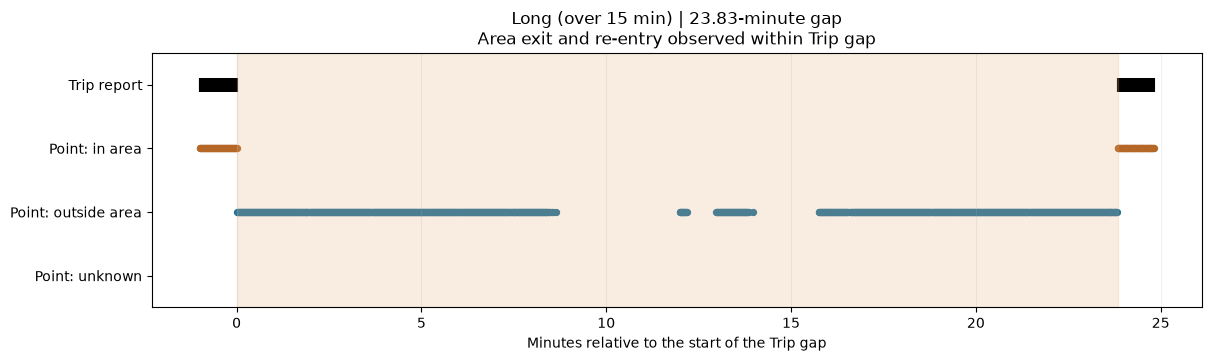

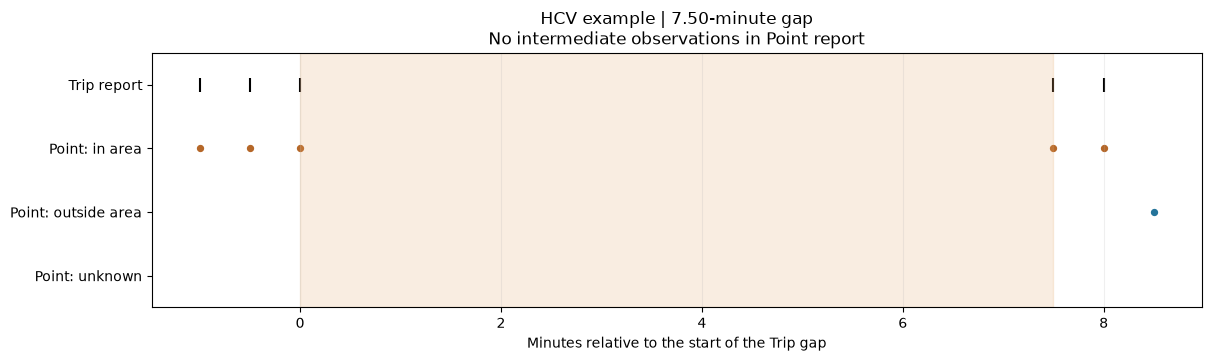

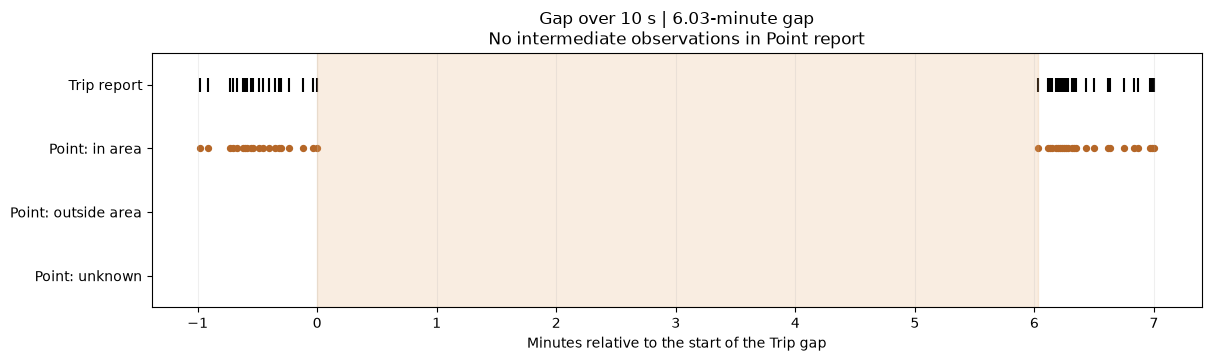

,Example,Gap (min),Matched Point rows,Reported full-trip points,Duplicate Point timestamps,...,Interior: unknown,Gap start in area,Gap end in area,Exit / re-entry evidence,Evidence
0,Long (over 15 min),23.83,1968,1968.0,0,...,0,True,True,True,Area exit and re-entry observed within Trip gap
1,HCV example,7.50,24,24.0,0,...,0,True,True,False,No intermediate observations in Point report
2,Gap over 10 s,6.03,1023,1023.0,0,...,0,True,True,False,No intermediate observations in Point report


In [21]:
gap_evidence_rows = []
local_timezone = MANIFEST['units']['timestamps_in']
for case in gap_cases:
    sample, index = case['sample'], case['index']
    start = pd.Timestamp(sample['times'][index]).tz_localize(local_timezone).tz_convert('UTC')
    end = pd.Timestamp(sample['times'][index + 1]).tz_localize(local_timezone).tz_convert('UTC')
    points = matched_points.loc[
        matched_points['VehicleID'].eq(sample['key'][0]) & matched_points['TripID'].eq(sample['key'][1])].copy()
    valid_points = points.dropna(subset=['time_utc']).sort_values('time_utc')
    interior = valid_points.loc[valid_points['time_utc'].gt(start) & valid_points['time_utc'].lt(end)]
    counts = interior['area_status'].value_counts()
    start_statuses = valid_points.loc[valid_points['time_utc'].eq(start), 'area_status']
    end_statuses = valid_points.loc[valid_points['time_utc'].eq(end), 'area_status']
    start_in_area = start_statuses.eq('In area').any()
    end_in_area = end_statuses.eq('In area').any()
    exit_reentry = (start_in_area and end_in_area and counts.get('Outside area', 0) > 0
                    and counts.get('In area', 0) == 0 and counts.get('Unknown', 0) == 0)

    if points.empty:
        interpretation = 'No matching Point records; unresolved'
    elif counts.get('In area', 0):
        interpretation = 'In-area observations present in Point report'
    elif exit_reentry:
        interpretation = 'Area exit and re-entry observed within Trip gap'
    elif len(interior) and counts.get('Outside area', 0) == len(interior):
        interpretation = 'Outside-area observations found within Trip gap'
    elif len(interior):
        interpretation = 'Intermediate observations with unknown area status'
    else:
        interpretation = 'No intermediate observations in Point report'
    metric = lookup.loc[sample['key']]
    gap_evidence_rows.append({'Example': sample['label'], 'Gap (min)': case['gap_s'] / 60,
        'Matched Point rows': len(points), 'Reported full-trip points': metric['full_trip_points'],
        'Duplicate Point timestamps': int(valid_points['time_utc'].duplicated().sum()),
        'Interior: in area': counts.get('In area', 0),
        'Interior: outside': counts.get('Outside area', 0),
        'Interior: unknown': counts.get('Unknown', 0),
        'Gap start in area': bool(start_in_area), 'Gap end in area': bool(end_in_area),
        'Exit / re-entry evidence': bool(exit_reentry), 'Evidence': interpretation})
    window = valid_points.loc[valid_points['time_utc'].between(start - pd.Timedelta(seconds=60), end + pd.Timedelta(seconds=60))]
    fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
    for status, y, color in [('In area', 2, '#b56728'), ('Outside area', 1, '#24749a'), ('Unknown', 0, '#888888')]:
        subset = window.loc[window['area_status'].eq(status)]
        x = (subset['time_utc'] - start).dt.total_seconds() / 60
        ax.scatter(x, np.full(len(x), y), s=18, color=color, label=f'Point: {status.lower()}')
    trip_times = pd.DatetimeIndex(sample['times']).tz_localize(local_timezone).tz_convert('UTC')
    nearby = trip_times[(trip_times >= start - pd.Timedelta(seconds=60)) & (trip_times <= end + pd.Timedelta(seconds=60))]
    ax.scatter((nearby - start).total_seconds() / 60, np.full(len(nearby), 3), marker='|', s=100, color='black', label='Trip timestamps')
    ax.axvspan(0, case['gap_s'] / 60, color='#e5a76b', alpha=.2)
    ax.set(yticks=[0, 1, 2, 3], yticklabels=['Point: unknown', 'Point: outside area', 'Point: in area', 'Trip report'],
           ylim=(-.5, 3.5), xlabel='Minutes relative to the start of the Trip gap',
           title=f"{sample['label']} | {case['gap_s'] / 60:.2f}-minute gap\n{interpretation}")
    ax.grid(axis='x', alpha=.2)
    plt.show()
gap_evidence = pd.DataFrame(gap_evidence_rows)
display(gap_evidence.round(2))


## 7. Individual Trajectories

### Select Example Trips

Select distinct seeded examples from short, medium, and long trips, plus an HCV and a trip containing a gap over 10 seconds when available. Check each example's duration, distance, point count, and largest gap before inspecting its plots.

These are diagnostic examples, not a representative sample. Selection requires aligned valid coordinates, increasing valid times, 10–10,000 points, and at least 30 seconds of reported duration. The paths cover the in-area portion only.


In [22]:
example_trips = select_diagnostic_samples()
lookup = trip_metrics.set_index(KEY_COLUMNS)
example_rows = []
for sample in example_trips:
    row = lookup.loc[sample['key']]
    example_rows.append({'Example': sample['label'], 'VehicleType': sample['vehicle_type'],
                         'VehicleID': sample['key'][0], 'TripID': sample['key'][1],
                         'StartTimestamp_UTC': sample['key'][2],
                         'Duration (min)': row['duration_s'] / 60,
                         'Distance (mi)': row['distance_mi'], 'Points': row['path_points'],
                         'Largest gap (s)': row['max_gap_s']})
display(pd.DataFrame(example_rows).round(2))


,Example,VehicleType,VehicleID,TripID,StartTimestamp_UTC,Duration (min),Distance (mi),Points,Largest gap (s)
0,Short (up to 2 min),CAR,985f9d16e6aaa6e97ca904414289117f,bc696d03f17b409da3a619536d0d464d,2026-08-27 17:44:48 UTC,1.32,0.21,14,25.0
1,Medium (2–15 min),HCV,ef3d6b3d041c78473cf335d1a3bdd36b,44065d3b934e5fa1f50961fefb7ab6a3,2026-08-19 00:04:52 UTC,9.00,6.95,10,60.0
2,Long (over 15 min),CAR,8bd573b5b7889c8f5edc80cfaef36949,175733f60f2999a4be6ec52774ec88a5,2026-08-01 12:17:47.922 UTC,34.55,10.27,643,1430.0
3,HCV example,HCV,27599faf159a2cdec1b8c632e7fbe095,dc92676d048e88e93e07a556fa2b63b7,2026-08-05 17:05:24 UTC,18.50,3.15,16,450.0
4,Gap over 10 s,CAR,03b8c42ac6e74252b17c0709f4ff837f,25e62736bf8774d9685f25006e461e84,2026-08-16 18:33:26 UTC,13.87,5.11,143,362.0


### Path, Speed, Acceleration, and Sampling for the Same Trip

Each figure shows one selected trip: its geographic path on the left and its speed, X/Y acceleration, and interval to the next observation on the right. The case name and full TripID identify the same record across every panel and the example table.

Path color represents elapsed time. Map lines break at time gaps over 10 seconds or steps over 100 meters; all observed positions remain visible. Time-series lines break at gaps over 10 seconds or missing channel values. Shading marks long time intervals; no values are interpolated or smoothed. The interval dot is placed at the start of its interval, using a logarithmic vertical axis.

Speed is supplied in mph and acceleration in g. X/Y retain their source field names without assuming axis direction. Missing channels are labeled explicitly. Paths cover the in-area portion only.


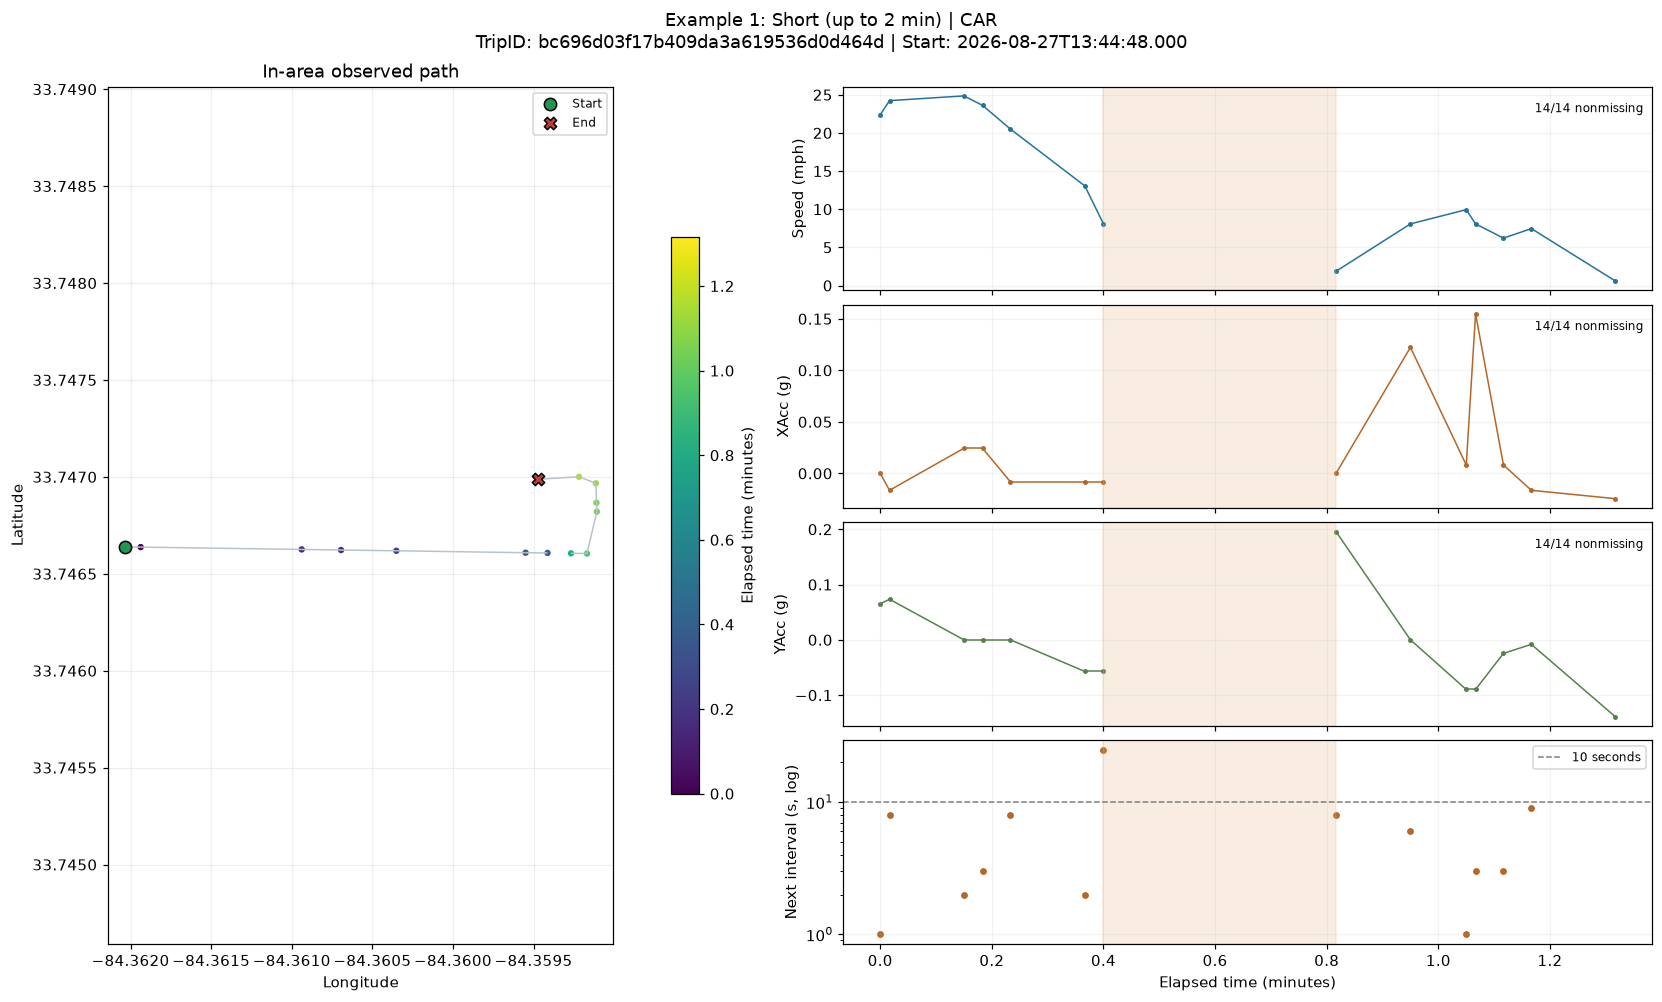

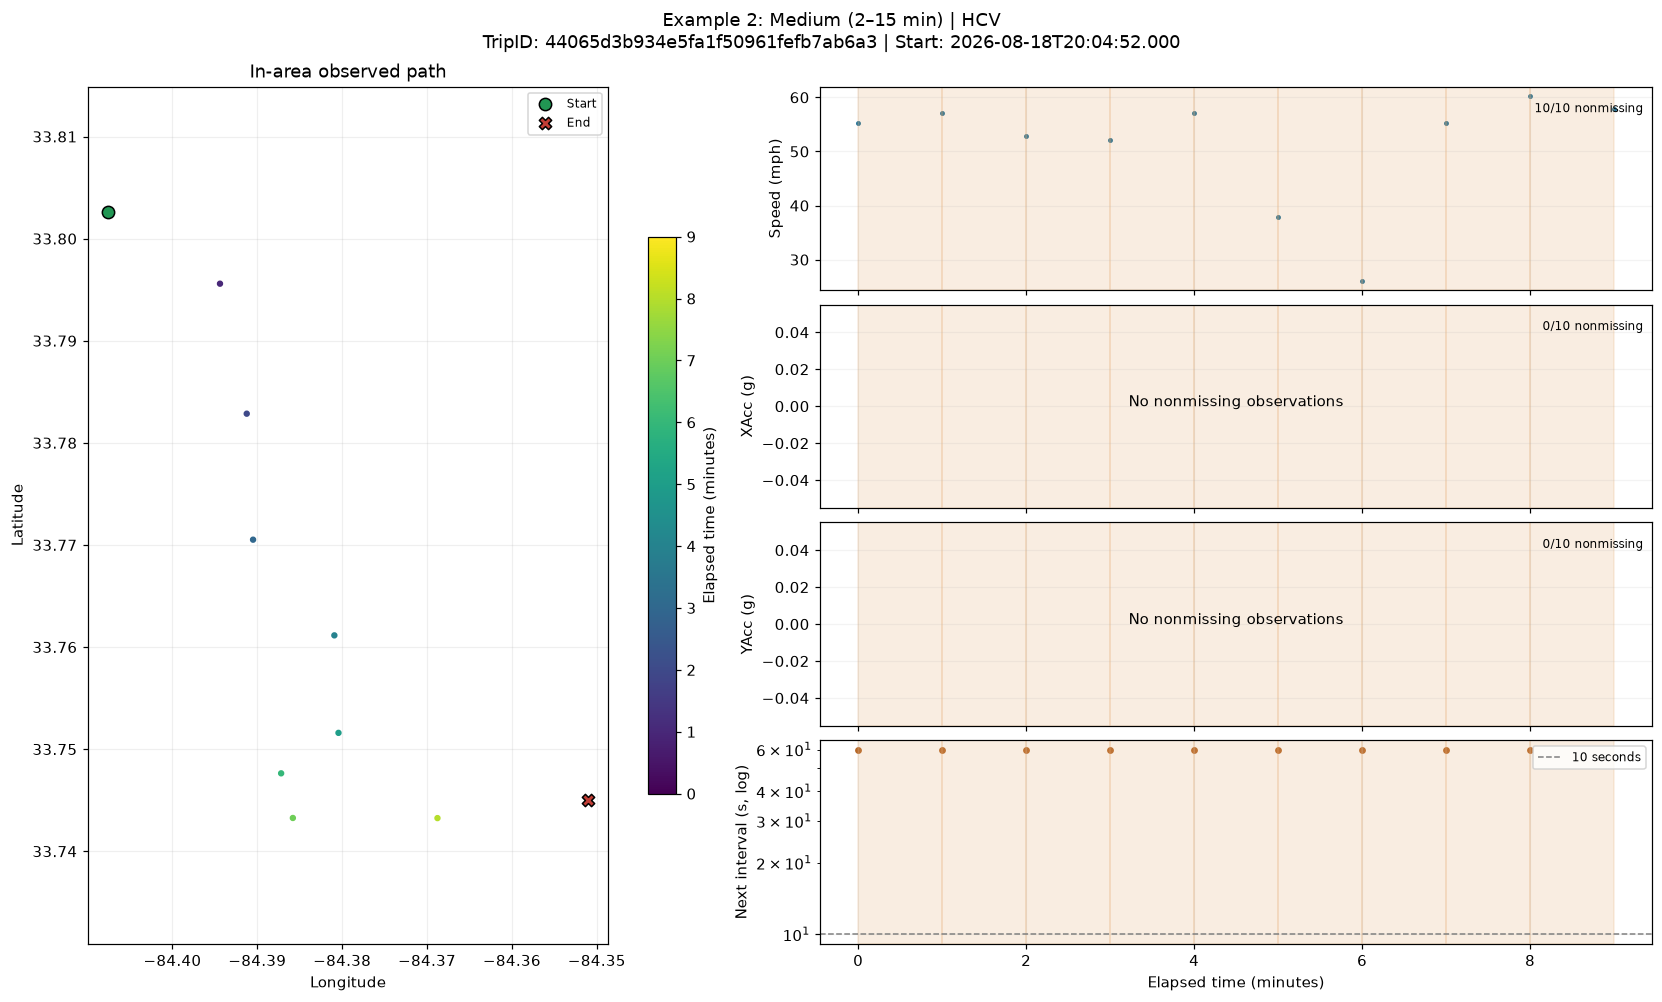

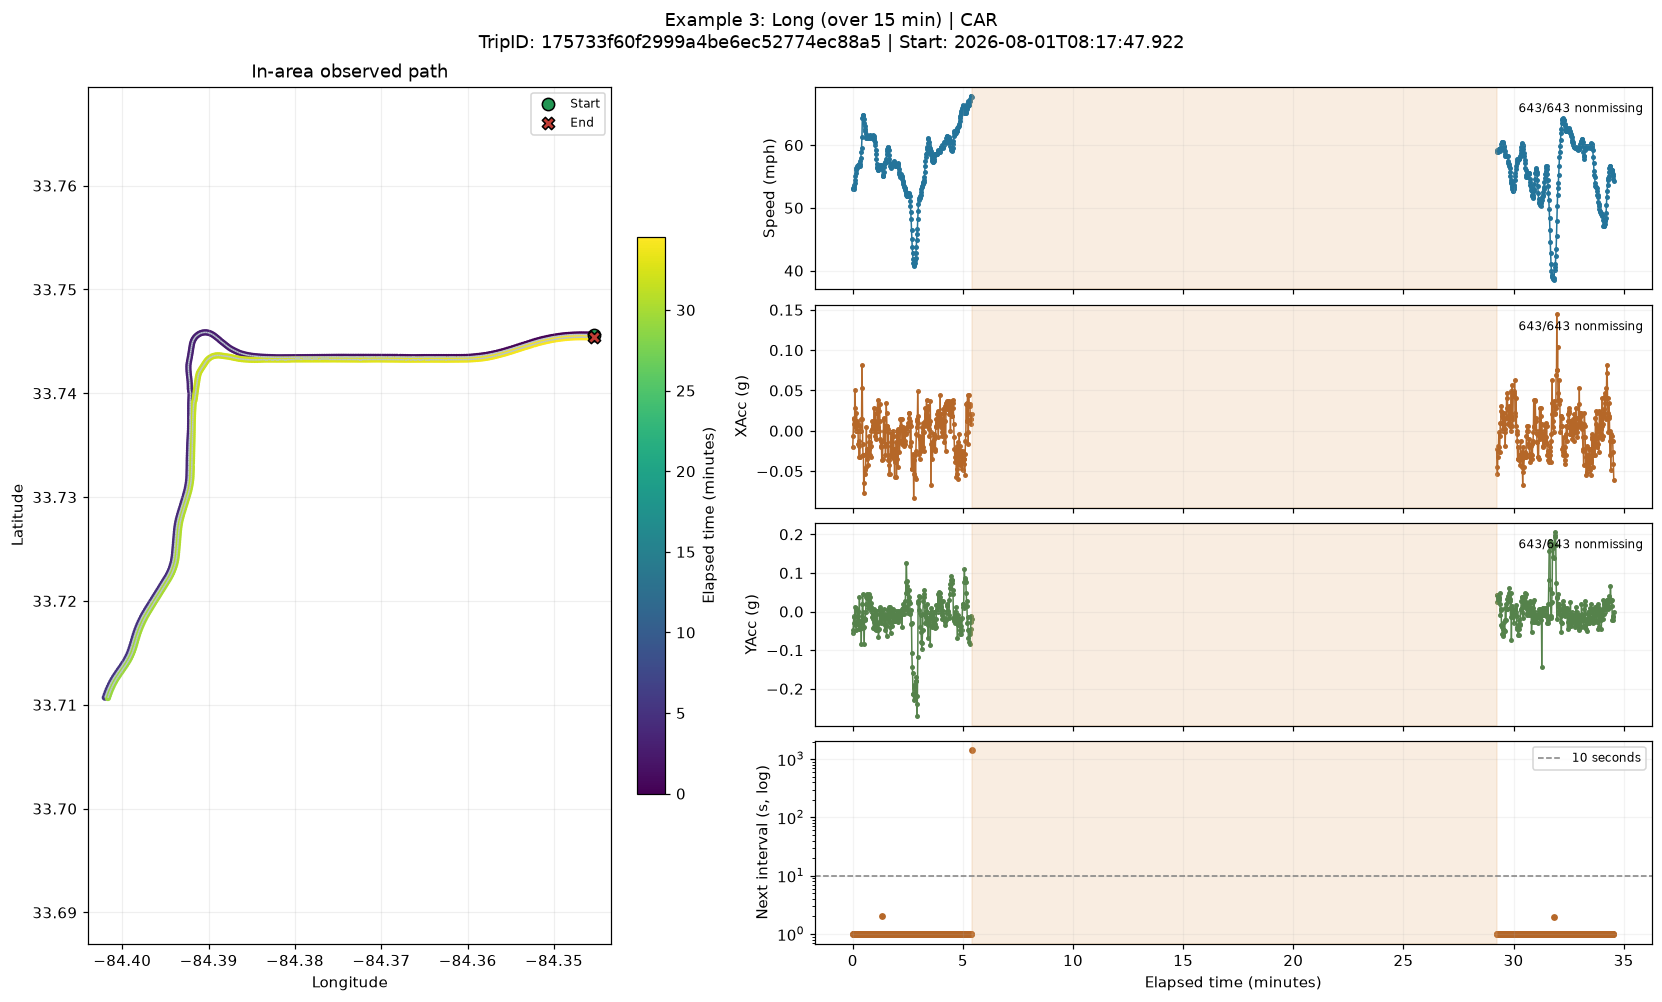

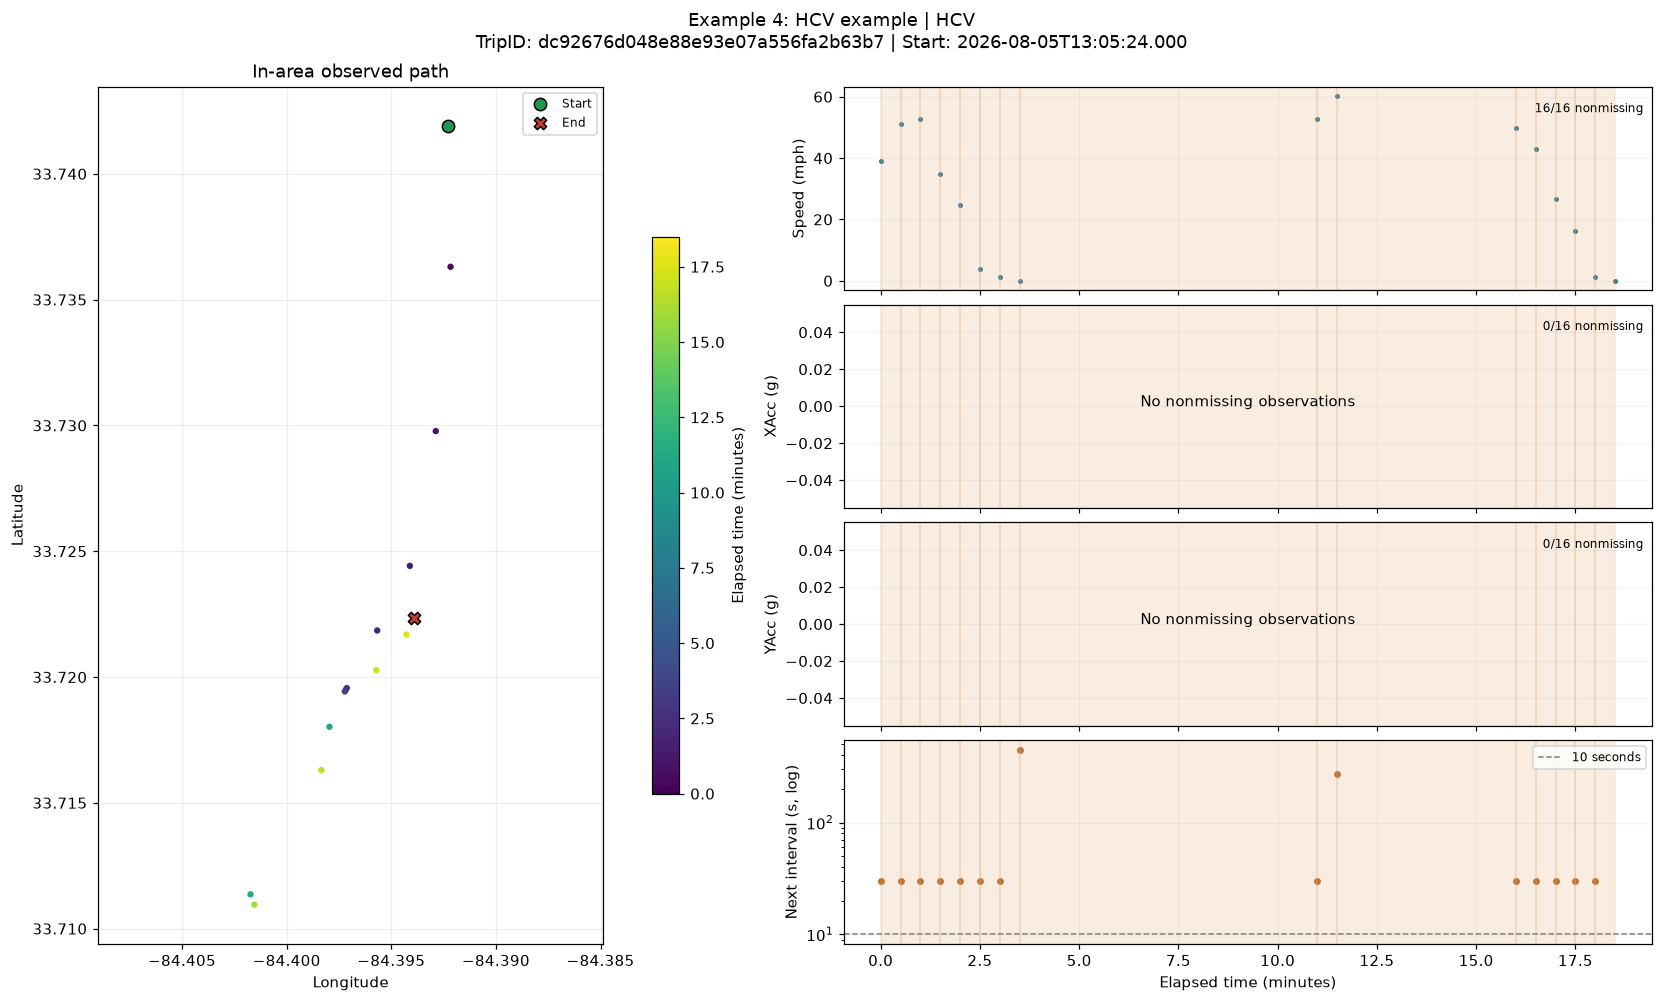

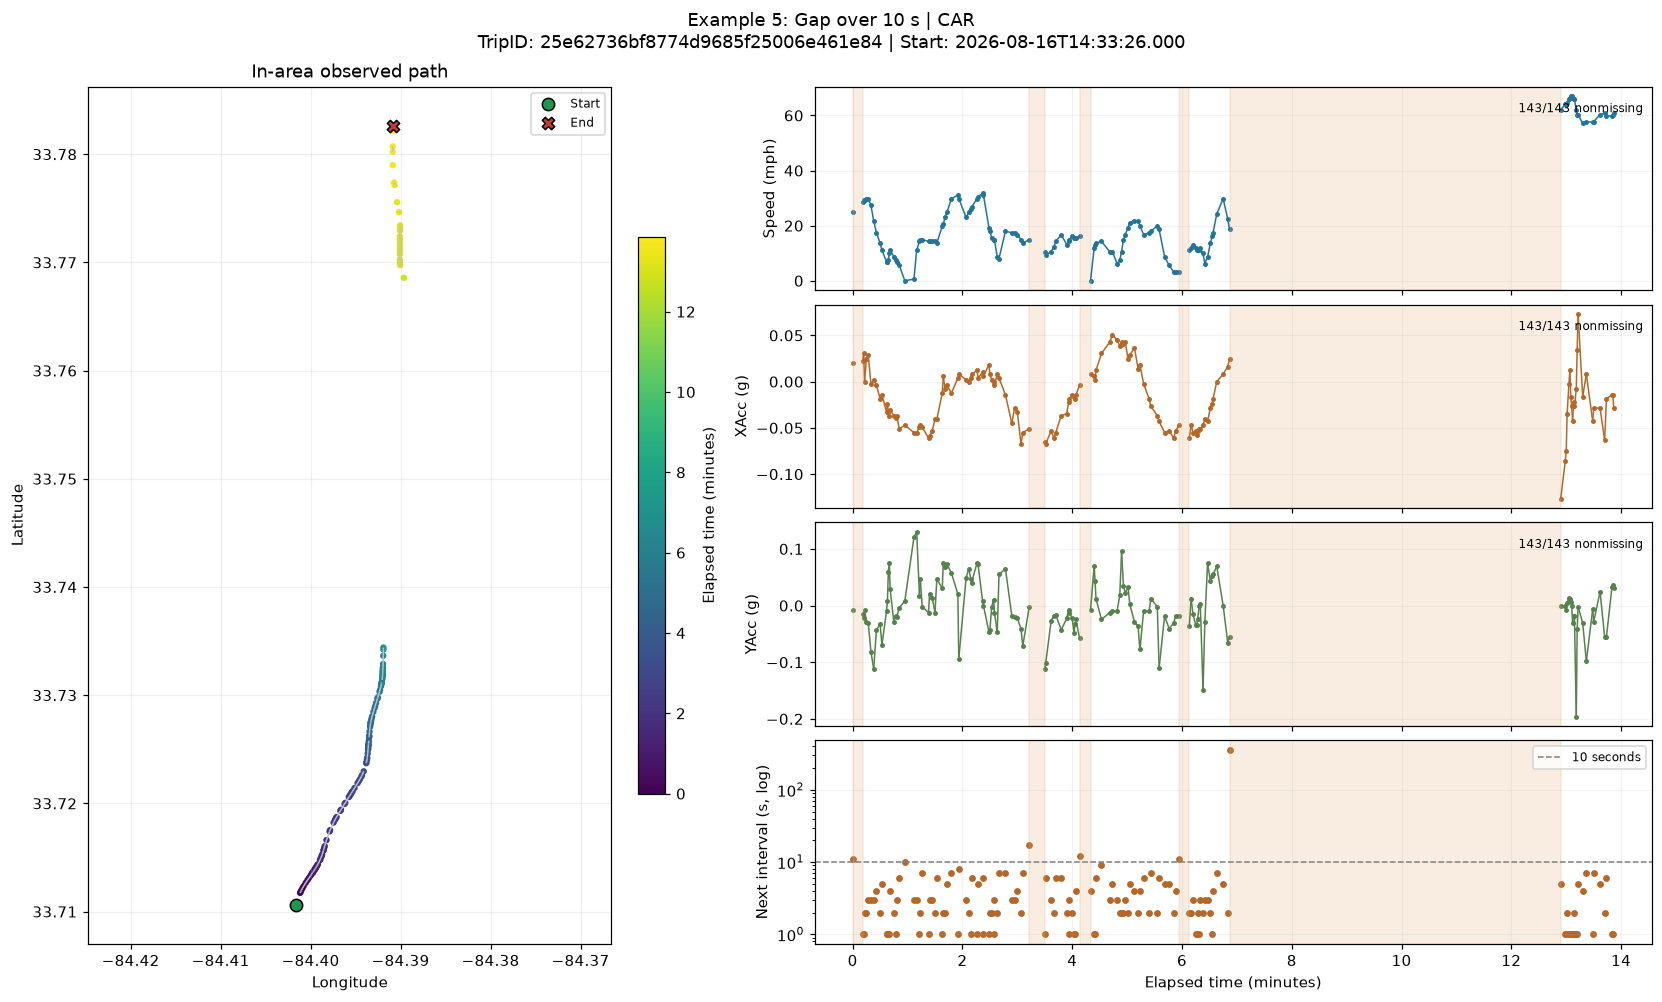

In [15]:
from matplotlib.collections import LineCollection

for case_number, sample in enumerate(example_trips, 1):
    coords, times = sample['coords'], sample['times']
    elapsed_s = (times - times[0]) / np.timedelta64(1, 's')
    elapsed_min = elapsed_s / 60
    intervals = np.diff(elapsed_s)
    long_gap = intervals > GAP_THRESHOLD_S
    path_links = (intervals > 0) & ~long_gap & (great_circle_steps(coords) <= STEP_THRESHOLD_M)
    fig = plt.figure(figsize=(15, 9), constrained_layout=True)
    grid = fig.add_gridspec(4, 2, width_ratios=[1, 1.6])
    map_ax = fig.add_subplot(grid[:, 0])
    axes = [fig.add_subplot(grid[j, 1]) for j in range(4)]
    for ax in axes[1:]:
        ax.sharex(axes[0])
    map_segments = np.stack([coords[:-1], coords[1:]], axis=1)
    map_ax.add_collection(LineCollection(map_segments[path_links], colors='#b8c4cd', linewidths=1))
    path_points = map_ax.scatter(coords[:, 0], coords[:, 1], c=elapsed_min, cmap='viridis', s=10)
    map_ax.scatter(*coords[0], color='#219653', s=65, edgecolor='black', label='Start', zorder=3)
    map_ax.scatter(*coords[-1], color='#c13d35', marker='X', s=65, edgecolor='black', label='End', zorder=3)
    map_ax.set_aspect(1 / np.cos(np.radians(coords[:, 1].mean())), adjustable='datalim')
    map_ax.ticklabel_format(useOffset=False)
    map_ax.set(xlabel='Longitude', ylabel='Latitude', title='In-area observed path')
    map_ax.legend(fontsize=8)
    map_ax.grid(alpha=.2)
    fig.colorbar(path_points, ax=map_ax, label='Elapsed time (minutes)', shrink=.65)

    for ax, channel, ylabel, color in zip(axes[:3], ['speed', 'xacc', 'yacc'],
             ['Speed (mph)', 'XAcc (g)', 'YAcc (g)'], ['#24749a', '#b56728', '#55824b']):
        values = sample[channel]
        if len(values) != len(times):
            ax.text(.5, .5, 'Channel and timestamp lengths differ', transform=ax.transAxes, ha='center')
        else:
            valid = np.isfinite(values)
            links = valid[:-1] & valid[1:] & (intervals > 0) & ~long_gap
            segments = np.stack([np.column_stack((elapsed_min[:-1], values[:-1])),
                                 np.column_stack((elapsed_min[1:], values[1:]))], axis=1)
            ax.add_collection(LineCollection(segments[links], colors=color, linewidths=1))
            ax.scatter(elapsed_min[valid], values[valid], s=5, color=color)
            ax.autoscale_view()
            ax.text(.99, .92, f'{valid.sum():,}/{len(values):,} nonmissing', transform=ax.transAxes,
                    ha='right', va='top', fontsize=8)
            if not valid.any():
                ax.text(.5, .5, 'No nonmissing observations', transform=ax.transAxes, ha='center')
        ax.set_ylabel(ylabel)
    positive = intervals > 0
    axes[3].scatter(elapsed_min[:-1][positive], intervals[positive], s=12, color='#b56728')
    axes[3].axhline(GAP_THRESHOLD_S, color='gray', ls='--', lw=1, label='10 seconds')
    axes[3].set(yscale='log', ylabel='Next interval (s, log)', xlabel='Elapsed time (minutes)')
    axes[3].legend(loc='upper right', fontsize=8)
    for ax in axes:
        for j in np.flatnonzero(long_gap):
            ax.axvspan(elapsed_min[j], elapsed_min[j + 1], color='#e5a76b', alpha=.2)
        ax.grid(alpha=.15)
    for ax in axes[:-1]:
        ax.tick_params(labelbottom=False)
    fig.suptitle(f"Example {case_number}: {sample['label']} | {sample['vehicle_type']}\n"
                 f"TripID: {sample['key'][1]} | Start: {times[0]}", fontsize=12)
    plt.show()


In [ ]:
import traci
import pandas as pd

traci.start(["sumo", "-c", str(CONFIG_FILE)])

records = []

try:
    while traci.simulation.getMinExpectedNumber() > 0:
        traci.simulationStep()

        records.append({
            "time": traci.simulation.getTime(),
            "phase": traci.trafficlight.getPhase("center"),
            "north": traci.edge.getLastStepHaltingNumber("north_in"),
            "south": traci.edge.getLastStepHaltingNumber("south_in"),
            "east": traci.edge.getLastStepHaltingNumber("east_in"),
            "west": traci.edge.getLastStepHaltingNumber("west_in"),
        })

finally:
    traci.close()

df_signal = pd.DataFrame(records)

df_signal["NS_waiting"] = df_signal["north"] + df_signal["south"]
df_signal["EW_waiting"] = df_signal["east"] + df_signal["west"]

display(df_signal.head(20))

 Retrying in 1 seconds
Step #653.00 (0ms ?*RT. ?UPS, TraCI: 0ms, vehicles TOT 200 ACT 0 BUF 0)                   


,time,phase,north,south,east,west,NS_waiting,EW_waiting
0,1.0,0,0,0,0,0,0,0
1,2.0,0,0,0,0,0,0,0
2,3.0,0,0,0,0,0,0,0
3,4.0,0,0,0,0,0,0,0
4,5.0,0,0,0,0,0,0,0
5,6.0,0,0,0,0,0,0,0
6,7.0,0,0,0,0,0,0,0
7,8.0,0,0,0,0,0,0,0
8,9.0,0,0,0,0,0,0,0
9,10.0,0,0,0,0,0,0,0
